# Arm and Hand Kinematics Decoding for Online Invasive BCI

**Source-only GitHub edition.** This copy preserves the analysis code and saved notebook outputs. Raw recordings, model weights, evaluation datasets, supplied reference trajectories and third-party MuJoCo model assets are not included. Viewing saved outputs does not require those files; rerunning the complete analysis does. See `README.md` for the external-input layout and setup instructions.

This notebook reproduces the results, figures and tables of the master thesis *Decoding Hand and Arm Kinematics for Online Invasive BCI*. The saved outputs come from the original thesis execution and follow its chapters. Every figure is drawn here, from the saved evaluations of the two runs, and is also written to `figures/` (vector PDF, 300 dpi PNG and a CSV with the plotted numbers); the tables are written to `tables/`.

**How to run it** (details in `README.md`): create a Python 3.10 virtual environment, install `requirements.txt`, select the environment as the notebook kernel (for example in VS Code: *Select Kernel* → *Python Environments* → `.venv`) and choose *Run All*.

**Notebook organization and implementation**

| Guideline | Where |
|---|---|
| 1. One cell that imports all libraries | Section 1 |
| 2. One cell with all parameters, grouped and commented; paths relative to the notebook | Section 2 |
| 3. Data loading and quick data inspection | Section 3 (thesis Chapter 3) |
| Training code present but commented out; the trained models are loaded below it | Section 4.3 (thesis Chapter 4) |
| Larger functions in separate `.py` files; smaller functions written in the notebook | small functions in Section 4.1, plotting and table functions in the section that uses them; larger functions in `plotting_functions/`, `run_v1/functions`, `run_v2/functions` |
| 4. Research question with the primary target, posture (`qpos`) | Section 5 (thesis Chapter 5) |
| 5. Secondary target: velocity (`qvel`) | Section 6 |
| 6. Secondary target: position + velocity (`qpos` + `qvel`) | Section 7 |
| 7. Simulation of the reference and the decoded movement next to each other, with parameters that select the recording day, block, trial and repetition from the test set | Section 9 (thesis Chapter 6) |
| 8. Summary of the results reported in the thesis | Section 11 (thesis Chapter 7) and Appendices A–E |
| Python and library versions | `python_and_library_versions.txt` (written by Section 1) |

Each research-question section starts with a markdown cell that states the question and the method, and ends with a short answer.

**The two runs.** The benchmark was trained twice with identical data, splits, models and settings. The runs differ in how the elapsed trial time is given to the decoders: **V1** uses the position within the cued trial, *t / (T − 1)*, and **V2** a clock from trial onset, *t / 600* (6 s at 100 Hz). In both runs, configurations are selected on validation data.

## 1. Libraries

In [1]:
%matplotlib inline
%config InlineBackend.figure_format = 'retina'

# Standard library
import json, os, sys, platform, importlib.metadata, subprocess
from pathlib import Path

# Scientific stack
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch, Polygon, Circle, Ellipse, Rectangle, FancyBboxPatch, FancyArrowPatch
from matplotlib.colors import to_rgb
from scipy.spatial import ConvexHull
import torch
from IPython.display import display, Markdown, Image

# Larger thesis functions: loading and selecting the saved results, colours and figure saving,
# MuJoCo simulation, loading the trained models and the 32-joint trajectory pages
from plotting_functions.results import (RUNS, RUN_TITLE, SPLITS, SPLIT_SHORT, SPLIT_LONG, OBJECTS, OBJECT_LABEL,
                                        DIRECT, FAMILY_LABEL, TARGET_LABEL, load_run, select, candidate, pca_tag,
                                        describe, test_trials)
from plotting_functions.style import (FAMILY_COLOR, RUN_COLOR, OBJECT_COLOR, LIMB_COLOR, RAW_GREY, FILTER_GREEN,
                                      limb, save, setup)
from plotting_functions import simulation, models, presentation
setup()

# Record the Python and library versions: training machine (from the run records) and this execution
packages = ['numpy', 'pandas', 'scipy', 'scikit-learn', 'torch', 'matplotlib', 'mujoco', 'Pillow', 'PyYAML', 'nbformat', 'ipykernel']
versions = {'python': platform.python_version(), 'platform': platform.platform()}
versions.update({p: importlib.metadata.version(p) for p in packages})
training = json.loads(Path('run_v2/results/provenance.json').read_text())
lines = ['# Training environment (recorded while the models were trained, Ubuntu)',
         'python==' + training['python'].split()[0], 'platform==' + training['platform']]
lines += [f'{k}=={v}' for k, v in training['versions'].items()]
lines += ['', '# Environment of the last execution of this notebook'] + [f'{k}=={v}' for k, v in versions.items()]
Path('python_and_library_versions.txt').write_text('\n'.join(lines) + '\n')
print('\n'.join(lines))

# Training environment (recorded while the models were trained, Ubuntu)
python==3.10.12
platform==Linux-6.8.0-138-generic-x86_64-with-glibc2.35
numpy==1.26.4
pandas==2.2.3
scipy==1.13.1
scikit-learn==1.4.2
torch==2.2.2+cpu
matplotlib==3.8.4
PyYAML==6.0.2

# Environment of the last execution of this notebook
python==3.10.12
platform==macOS-26.5-arm64-arm-64bit
numpy==1.26.4
pandas==2.2.3
scipy==1.13.1
scikit-learn==1.4.2
torch==2.2.2
matplotlib==3.8.4
mujoco==3.8.1
Pillow==10.2.0
PyYAML==6.0.2
nbformat==5.10.4
ipykernel==6.21.3


## 2. Parameters
All paths are relative to this notebook. The data, preprocessing and training values are those used by the training code of both runs (thesis Chapter 4).

In [2]:
# --- Paths (relative to this notebook) ------------------------------------------------------
ROOT = Path('.')                        # repository root = folder of this notebook
RECORDINGS = 'data/patient_sessions'    # folder with the nine recording blocks (see data/README.md);
                                        # on the training machine, for example '/mnt/vmshare'
RECORDED_DURATIONS = 'data/recorded_attempt_durations.csv'   # attempt durations read on the recording machine
FIGURES = 'figures'                     # figures are written here (PDF + PNG + CSV with the plotted numbers)
TABLES = 'tables'                       # tables are written here (CSV + LaTeX)
NEW_TRAINING = 'new_training_results'   # output folder of V2 if training is re-run (Section 4.3)
TRAINING_PROFILE = 'full'               # 'full' = complete benchmark; 'smoke' = quick check with a few models

# --- Data --------------------------------------------------------------------------------------
SAMPLE_RATE_HZ = 100                    # one bin = 10 ms
NEURAL_CHANNELS = 256
POSTURE_COORDINATES = 32                # joint angles of the arm-and-hand model (qpos), in rad
BLOCKS = [f'{day}-block{b}' for day in ('20260630', '20260703', '20260707') for b in (1, 2, 3)]
DATE_LABEL = {20260630: 'Day 1', 20260703: 'Day 2', 20260707: 'Day 3'}

# --- Quick data inspection (Section 3): one recording block ------------------------------------
INSPECT_DAY = '20260630'                # recording day
INSPECT_BLOCK = 1                       # block of that day (1, 2 or 3)
INSPECT_OBJECT = 'big_v_cylinder'       # object of the raw trial shown (only with the recordings), see OBJECTS
INSPECT_REPETITION = 0                  # repetition of that trial, 0-based (0 = first of ten)

# --- Preprocessing (identical in both runs) -----------------------------------------------------
NEURAL_EMA_ALPHA = 0.15                 # causal smoothing of the neural input (time constant ~62 ms)
V2_CLOCK_BINS = 600                     # V2 time input: bins since onset / 600 (6 s)

# --- Models and training (identical in both runs) ----------------------------------------------
NEURAL_PCA_COMPONENTS = 64
KINEMATIC_PCA_COMPONENTS = 12
HIDDEN_SIZE, LFADS_FACTORS = 96, 32
TRANSFORMER_LAYERS, TRANSFORMER_HEADS, TRANSFORMER_FF, TRANSFORMER_DROPOUT = 2, 4, 384, 0.08
RIDGE_ALPHA = 100.0
LEARNING_RATE, WEIGHT_DECAY, BATCH_SIZE, MAX_EPOCHS, PATIENCE, GRAD_CLIP = 1e-3, 1e-4, 32, 70, 12, 1.0
DELTA_LOSS_WEIGHT, RECONSTRUCTION_LOSS_WEIGHT = 0.05, 0.025
OUTPUT_SMOOTHING_GRID = (1.0, 0.75, 0.55, 0.35)    # chosen per model on validation data (1.0 = none)
ONE_EURO = dict(min_cutoff_hz=1.0, beta=0.02, derivative_cutoff_hz=1.0)
SEED = 20260908

# --- Evaluation -----------------------------------------------------------------------------------
SELECTION_SCORE = 'val_qpos_R2'         # configurations are chosen on the validation posture R2

# --- Artificial-stream tests (Appendix A) --------------------------------------------------------
STREAM_SEED, FAKE_RATE_HZ, RATE_HZ = 20260803, 5.0, 100.0          # seed and Poisson rate of the artificial input
SHOWN = {0: 'Shoulder flexion', 3: 'Elbow', 12: 'Index MCP flexion', 22: 'Ring MCP flexion'}

# --- Simulation (Section 9): one held-out test trial ----------------------------------------------
SIM_DAY = '20260630'                    # recording day
SIM_BLOCK = 1                           # block of that day (1, 2 or 3)
SIM_TRIAL = 12                          # movement condition (trial index within the recordings)
SIM_REPETITION = 8                      # repetition index, 0-based (8 = repetition 9 of 10, a test repetition)
# The table printed in Section 9 lists every test trial with a saved replay.

# --- Diagram colours (TUM palette) ------------------------------------------------------------------
BLUE, LIGHT, GREY, ORANGE = '#005293', '#e8f0f8', '#5c6269', '#e37222'
VARIANT_COLORS = ['#005293', '#3070b3', '#64a0c8']              # movement variant of blocks 1, 2 and 3 (Figure 1)
OBJECT_GREY = '#8c939e'                                          # objects in the legend of Figure 1

## 3. Data loading and quick inspection (thesis Chapter 3)
The data set contains 540 attempted-movement trials: 3 recording days × 3 blocks × 6 objects × 10 repetitions. In every block, the participant attempted six reach-and-grasp movements, one toward each object, and each block used its own movement variant of every object, so that there are 18 distinct reach-and-grasp movements (6 objects × 3 variants). Each of them was performed in the same block on all three days, ten times per day: 18 movements × 10 repetitions × 3 days = 540 trials. All repetitions of one movement in one block share the same prescribed reference trajectory.

**Recordings and the first table.** The raw recordings are not part of the repository (they stay on the recording machine). The first table checks, for each of the nine blocks, whether its folder and its two data files are present at `RECORDINGS`. On a computer without the recordings, every entry is `False`; this is expected and changes nothing below, because all results are reproduced from the saved evaluations in `run_v1/results` and `run_v2/results`. The recordings are only needed for re-training (Section 4.3) and for the raw-trial plot at the end of Section 3.2, which is skipped when they are missing. To use them, copy or link the nine block folders into `data/patient_sessions` (see `data/README.md`), or set `RECORDINGS` to the folder that contains them.

**Selecting a block.** `INSPECT_DAY` and `INSPECT_BLOCK` (Section 2) choose the block that is shown in detail, and `INSPECT_OBJECT` and `INSPECT_REPETITION` the raw trial of that block. The table of its six movements comes from the saved trial index and works without the recordings; the raw-trial plot reads the block folder `RECORDINGS/<day>-block<block>` with the loader of the training code. Both were tested on a synthetic copy of the nine block folders with the same file format.

### 3.1 Functions for the data overview and the recording protocol

In [3]:
# Data overview
def recording_status(root, recordings):
    """Which of the nine block folders are present at the configured relative path."""
    base = Path(root) / recordings
    return pd.DataFrame([dict(block=b, folder_found=(base / b).is_dir(),
                              neural_file=(base / b / 'trials-attempt-resampled.pkl').is_file(),
                              kinematics_file=(base / b / 'all_attempt.pkl').is_file()) for b in BLOCKS])


def trial_overview(index, out):
    """Trials per block and object, and the trial durations per object."""
    counts = index.pivot_table(index='session', columns='object_name', values='repeat', aggfunc='size').reindex(columns=OBJECTS)
    fig, axes = plt.subplots(1, 2, figsize=(10, 4.4), gridspec_kw={'width_ratios': [1.05, 1]})
    fig.subplots_adjust(left=.14, right=.98, bottom=.25, top=.9, wspace=.85)
    axes[0].imshow(counts.to_numpy(), cmap='Blues', vmin=0, vmax=14, aspect='auto')
    for (i, j), v in np.ndenumerate(counts.to_numpy()):
        axes[0].text(j, i, int(v), ha='center', va='center', fontsize=10)
    axes[0].set_xticks(range(6), [OBJECT_LABEL[o] for o in OBJECTS], rotation=45, ha='right', fontsize=9.5)
    axes[0].set_yticks(range(len(counts)), [s.replace('-block', ', block ') for s in counts.index], fontsize=9.5)
    axes[0].set_title('Trials per block and object')
    data = [index[index.object_name.eq(o)].n_time / 100 for o in OBJECTS]
    parts = axes[1].boxplot(data, vert=False, patch_artist=True, widths=.6, medianprops=dict(color='#222222'))
    for patch, o in zip(parts['boxes'], OBJECTS):
        patch.set_facecolor(OBJECT_COLOR[o])
    axes[1].set_yticks(range(1, 7), [OBJECT_LABEL[o].replace('\n', ' ') for o in OBJECTS], fontsize=9.5)
    axes[1].invert_yaxis()
    axes[1].set_xlabel('Trial duration (s)')
    axes[1].set_title('Trial durations')
    axes[1].grid(axis='x', alpha=.25)
    return save(fig, out, 'data_overview', counts.reset_index())


def raw_trial(root, recordings, out, block='20260630-block1', object_name='big_v_cylinder', repetition=0):
    """Neural raster and reference posture of one raw trial (needs the recordings)."""
    code = str(Path(root) / 'run_v2/functions')
    sys.path.insert(0, code)
    try:
        # The training code is added to the import path at run time (line above). The editor cannot see this path
        # in advance and may underline the import in red; the notebook still runs, so the warning is silenced here.
        from decoder_core.data import load_dataset  # type: ignore
        ds = load_dataset(Path(root) / recordings / block)
    finally:
        # Both runs ship a package named decoder_core: unload this one so that the models of either run load later.
        sys.path.remove(code)
        for name in [m for m in sys.modules if m == 'decoder_core' or m.startswith('decoder_core.')]:
            del sys.modules[name]
    t = next(x for x in ds.trials if x.object_name == object_name and x.repeat == repetition)
    time = np.arange(t.n_time) / 100
    fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
    rows, cols = np.nonzero(t.neural.T > 0)
    axes[0].scatter(time[cols], rows, s=.6, marker='|', color='#222222')
    axes[0].set_ylabel('Neural channel')
    label = OBJECT_LABEL[object_name].replace('\n', ' ').lower()
    axes[0].set_title(f'{block}, {label}, repetition {repetition + 1}: threshold crossings per 10 ms bin')
    for j in range(32):
        axes[1].plot(time, t.qpos[:, j], lw=1)
    axes[1].set_ylabel('Reference posture (rad)')
    axes[1].set_xlabel('Time from trial onset (s)')
    return save(fig, out, 'raw_trial_example')

In [4]:
# Recording protocol (Figure 1 of the thesis): days as rows, blocks as columns (one platform per block), the six objects rendered
# with the MuJoCo model of the task (simulation.object_sprites), coloured by the movement variant of the block
OBJECT_NAMES = ['small\nball', 'large\nball', 'small vertical\ncylinder', 'large vertical\ncylinder',
                'small horizontal\ncylinder', 'large horizontal\ncylinder']
OBJECT_SIZE = [.013, .034, .076, .082, .132, .14]               # largest half-extent of each object in the scene (m)
DAYS = [('Day 1', '30 June'), ('Day 2', '3 July'), ('Day 3', '7 July')]


def tint(color, amount):
    """Mix a colour with white (amount 0: colour, 1: white)."""
    rgb = np.array(to_rgb(color))
    return tuple(rgb + (1 - rgb) * amount)


def clean_sprite(image):
    """Crop a MuJoCo render to its object and soften the binary mask so that the edges resample smoothly."""
    rows, cols = np.nonzero(image[..., 3])
    image = image[rows.min() - 2:rows.max() + 3, cols.min() - 2:cols.max() + 3]
    rgb, inside = image[..., :3] / 255, image[..., 3] > 0
    filled, known = rgb * inside[..., None], inside.copy()
    for _ in range(3):                                          # spread the object colour into the background pixels
        total, count = np.zeros_like(rgb), np.zeros(inside.shape)
        for shift in [(1, 0), (-1, 0), (0, 1), (0, -1)]:
            total += np.roll(filled * known[..., None], shift, (0, 1))
            count += np.roll(known, shift, (0, 1))
        new = ~known & (count > 0)
        filled[new] = total[new] / count[new][:, None]
        known |= new
    alpha = np.pad(inside.astype(float), 1, mode='edge')
    alpha = sum(alpha[1 + dy:alpha.shape[0] - 1 + dy, 1 + dx:alpha.shape[1] - 1 + dx]
                for dy in (-1, 0, 1) for dx in (-1, 0, 1)) / 9
    return np.dstack([filled, alpha])


def object_row(ax, images, x0, x1, base, height_scale, pad=.12, even=False, z=3):
    """Six objects side by side on a base line (packed, or centred in equal slots); display size grows sublinearly
    with the physical size."""
    size = [(s / max(OBJECT_SIZE)) ** .5 for s in OBJECT_SIZE]
    dims = [(im.shape[1] / max(im.shape[:2]) * s, im.shape[0] / max(im.shape[:2]) * s) for im, s in zip(images, size)]
    slot = (x1 - x0) / len(images)
    scale = min(height_scale, (slot - pad) / max(w for w, _ in dims) if even else (x1 - x0 - pad * 5) / sum(w for w, _ in dims))
    x, centres = x0, []
    for k, (im, (w, h)) in enumerate(zip(images, dims)):
        w, h = w * scale, h * scale
        if even:
            x = x0 + (k + .5) * slot - w / 2
        ax.add_patch(Ellipse((x + w / 2, base + .01), w * .85, .07, fc=(0, 0, 0, .1), ec='none', zorder=z - .5))
        ax.imshow(im, extent=(x, x + w, base, base + h), zorder=z, interpolation='antialiased')
        centres.append(x + w / 2)
        x += w + pad
    return centres


def platform(ax, x0, y0, width, color, depth=.74, skew=.46, thickness=.13):
    """Flat block platform seen slightly from above: top face, coloured front edge and side; returns the height of
    the line on which the objects stand."""
    rgb = np.array(to_rgb(color))
    w = width - skew
    ax.add_patch(Polygon([(x0 + .08, y0 - thickness - .06), (x0 + w + .1, y0 - thickness - .06),
                          (x0 + w + skew + .1, y0 + depth - thickness - .06), (x0 + w + skew, y0 + depth)],
                         fc=(0, 0, 0, .05), ec='none', zorder=.8))                       # soft drop shadow
    ax.add_patch(Polygon([(x0, y0), (x0 + w, y0), (x0 + w + skew, y0 + depth), (x0 + skew, y0 + depth)],
                         fc=tint(color, .9), ec=tint(color, .55), lw=1, zorder=1))       # top face
    ax.add_patch(Polygon([(x0, y0 - thickness), (x0 + w, y0 - thickness), (x0 + w, y0), (x0, y0)],
                         fc=color, ec=color, lw=.6, zorder=1.1))                         # front edge: movement variant
    ax.add_patch(Polygon([(x0 + w, y0 - thickness), (x0 + w + skew, y0 + depth - thickness), (x0 + w + skew, y0 + depth),
                          (x0 + w, y0)], fc=tuple(rgb * .7), ec=tuple(rgb * .7), lw=.6, zorder=1.1))   # side
    for k in (1, 2):                                                                     # faint depth lines on the floor
        f = k / 3
        ax.plot([x0 + skew * f + .06, x0 + w + skew * f - .06], [y0 + depth * f] * 2, color=tint(color, .7), lw=.6, zorder=1.2)
    return y0 + depth * .33


def protocol(out, sprites):
    """Recording protocol: a grid of days (rows) and blocks (columns) with MuJoCo renders of the six objects."""
    W, H = 14.2, 7.95
    fig = plt.figure(figsize=(W, H))
    ax = fig.add_axes([0, 0, 1, 1]); ax.set_xlim(0, W); ax.set_ylim(0, H); ax.axis('off')
    images = {key: clean_sprite(image) for key, image in sprites.items()}
    left, card_w, card_h, gap_x, gap_y, top = 1.75, 3.75, 1.36, .28, .24, 6.75
    ax.text(.35, 7.62, 'Recording protocol: three days × three blocks, one movement variant per block', fontsize=17,
            fontweight='bold', color=BLUE, va='center')
    for b, color in enumerate(VARIANT_COLORS):                  # column headers
        cx = left + b * (card_w + gap_x) + card_w / 2
        ax.add_patch(FancyBboxPatch((cx - .62, top + .2), 1.24, .36, boxstyle='round,pad=0,rounding_size=.18',
                                    fc=color, ec='none'))
        ax.text(cx, top + .38, f'Block {b + 1}', ha='center', va='center', fontsize=12, color='white', fontweight='bold')
        ax.text(cx, top + .07, f'movement variant {b + 1}', ha='center', va='center', fontsize=10, color=color)
    ax.plot([.62, .62], [top - .35, top - 2 * (card_h + gap_y) - card_h + .35], color='#c5d0dc', lw=2, zorder=1)
    for d, (day, date) in enumerate(DAYS):
        y0 = top - .2 - (d + 1) * card_h - d * gap_y
        cy = y0 + .62
        ax.scatter([.62], [cy], s=95, color=BLUE, zorder=2, edgecolor='white', linewidth=2)
        ax.text(.85, cy + .12, day, ha='left', va='center', fontsize=12.5, fontweight='bold', color='#1f2937')
        ax.text(.85, cy - .16, date, ha='left', va='center', fontsize=10, color=GREY)
        for b, color in enumerate(VARIANT_COLORS):
            x0 = left + b * (card_w + gap_x)
            base = platform(ax, x0, y0 + .24, card_w, color)
            object_row(ax, [images[(name, b)] for name in OBJECTS], x0 + .42, x0 + card_w - .38, base, 1.08)
            ax.add_patch(FancyBboxPatch((x0 + card_w - 1.33, y0 + .05), .78, .25, boxstyle='round,pad=0,rounding_size=.08',
                                        fc='white', ec=color, lw=1.1, zorder=4))
            ax.text(x0 + card_w - .94, y0 + .175, '×10 each', ha='center', va='center', fontsize=9, color=color,
                    fontweight='bold', zorder=5)
        ax.text(left + 3 * card_w + 2 * gap_x + .18, cy, '180\ntrials', ha='left', va='center', fontsize=9.5,
                color=GREY, linespacing=1.1)
    # legend of the objects and the trial count
    ly = top - .2 - 3 * card_h - 2 * gap_y - .45
    ax.text(.35, ly - .55, 'Task objects', fontsize=11, fontweight='bold', color='#1f2937', va='center')
    centres = object_row(ax, [images[(name, 'grey')] for name in OBJECTS], 1.7, 8.7, ly - .7, .95, pad=.25, even=True)
    for cx, name in zip(centres, OBJECT_NAMES):
        ax.text(cx, ly - .82, name, ha='center', va='top', fontsize=9, color=GREY, linespacing=1.05)
    chips = [('3', 'days'), ('3', 'blocks'), ('6', 'objects'), ('10', 'repetitions'), ('540', 'trials')]
    x = 9.1
    for k, (number, unit) in enumerate(chips):
        last = k == len(chips) - 1
        ax.add_patch(FancyBboxPatch((x, ly - 1.35), .74 if not last else .86, .78, boxstyle='round,pad=0,rounding_size=.1',
                                    fc=BLUE if last else LIGHT, ec=BLUE, lw=1))
        cx = x + (.43 if last else .37)
        ax.text(cx, ly - .82, number, ha='center', va='center', fontsize=14, fontweight='bold', color='white' if last else BLUE)
        ax.text(cx, ly - 1.15, unit, ha='center', va='center', fontsize=8, color='white' if last else GREY)
        if not last:
            ax.text(x + .87, ly - .96, '=' if k == len(chips) - 2 else '×', ha='center', va='center', fontsize=13, color=GREY)
        x += 1.0
    save(fig, out, 'diagram_acquisition_protocol')

### 3.2 The trials, the protocol and one recording block

,block,folder_found,neural_file,kinematics_file
0,20260630-block1,False,False,False
1,20260630-block2,False,False,False
2,20260630-block3,False,False,False
3,20260703-block1,False,False,False
4,20260703-block2,False,False,False
5,20260703-block3,False,False,False
6,20260707-block1,False,False,False
7,20260707-block2,False,False,False
8,20260707-block3,False,False,False


540 trials | 9 blocks (3 days x 3 blocks) | 6 objects | 18 distinct reach-and-grasp movements (6 objects x 3 movement variants), each repeated 10 times on each of the 3 days: 18 x 10 x 3 = 540
ten repetitions of every movement condition: True
six objects in every block: True
same movement variants in a given block on every day: True
no movement variant shared between blocks: True
reference length differs between the days for 18 of 18 movement variants


Day 1  Day 2  Day 3
block object_name                          
1     big_ball           5.81   5.54   5.59
      big_h_cylinder     5.60   5.06   5.33
      big_v_cylinder     6.53   5.60   5.66
      small_ball         5.43   5.20   5.48
      small_h_cylinder   5.63   6.39   6.44
      small_v_cylinder   6.16   5.55   5.48
2     big_ball           5.53   5.54   5.55
      big_h_cylinder     5.54   5.54   5.49
      big_v_cylinder     5.57   5.30   5.45
      small_ball         5.24   5.10   5.43
      small_h_cylinder   5.77   5.58   5.84
      small_v_cylinder   5.58   5.36   5.53
3     big_ball           5.27   5.42   5.65
      big_h_cylinder     5.51   5.46   5.30
      big_v_cylinder     5.33   6.66   6.39
      small_ball         5.86   5.34   5.54
      small_h_cylinder   5.61   5.79   5.89
      small_v_cylinder   6.39   5.52   5.26

**Recording block 20260630-block1**

,gesture,object_name,repetitions,duration_s
0,0,small_h_cylinder,10,5.63
1,5,big_h_cylinder,10,5.60
2,6,big_ball,10,5.81
3,7,small_ball,10,5.43
4,12,big_v_cylinder,10,6.53
5,13,small_v_cylinder,10,6.16


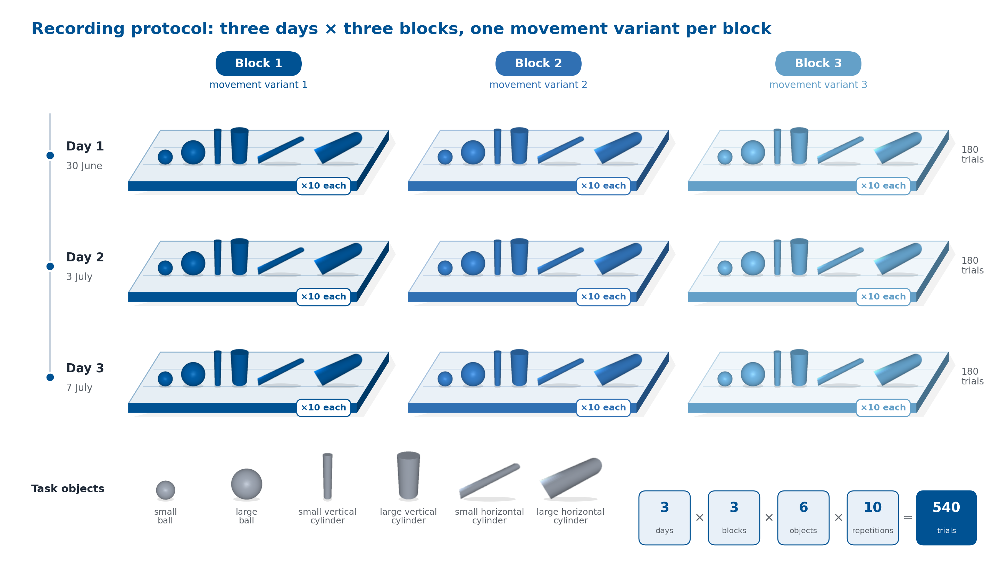

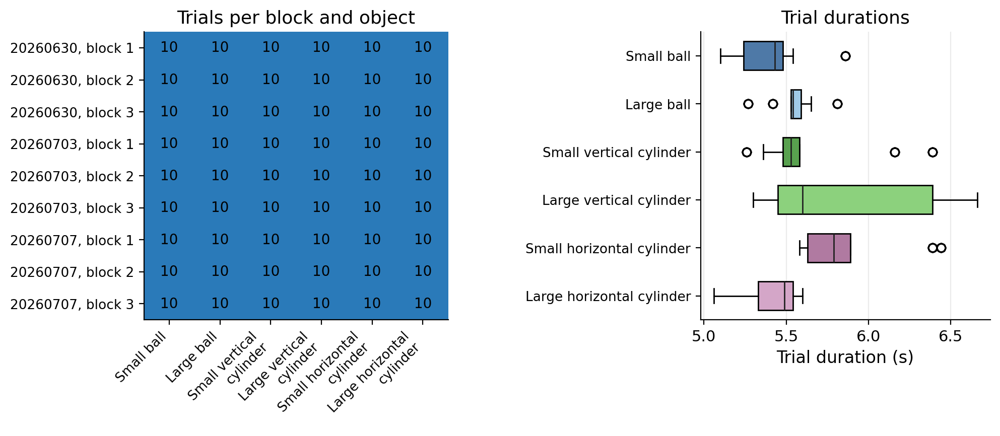

In [5]:
display(recording_status(ROOT, RECORDINGS))

# Trial index of both runs (identical data)
runs = {name: load_run(ROOT, name) for name in ['v1', 'v2']}
index = runs['v1']['index']
print(f'{len(index)} trials | {index.session.nunique()} blocks (3 days x 3 blocks) | {index.object_name.nunique()} objects | '
      f'{index.handle_id.nunique()} distinct reach-and-grasp movements (6 objects x 3 movement variants), '
      f'each repeated 10 times on each of the 3 days: 18 x 10 x 3 = {18 * 10 * 3}')

# Protocol check: six objects x ten repetitions per block, own movement variant per block, same variants every day
day_block = index.assign(day=index.session.str[:8], block=index.session.str[-1].astype(int))
variants = day_block.groupby(['block', 'day']).handle_id.apply(lambda s: tuple(sorted(set(s)))).unstack()
print('ten repetitions of every movement condition:', bool((day_block.groupby(['session', 'handle_id']).size() == 10).all()))
print('six objects in every block:', bool((day_block.groupby('session').object_name.nunique() == 6).all()))
print('same movement variants in a given block on every day:', bool((variants.nunique(axis=1) == 1).all()))
print('no movement variant shared between blocks:', len(set().union(*variants.iloc[:, 0])) == 18)

# The same variant on different days: same movement, but its reference trajectory was not identical (length in s)
lengths = day_block.groupby(['block', 'object_name', 'day']).n_time.first().unstack() / SAMPLE_RATE_HZ
lengths.columns = [DATE_LABEL[int(d)] for d in lengths.columns]
print(f'reference length differs between the days for {(lengths.nunique(axis=1) > 1).sum()} of {len(lengths)} movement variants')
display(lengths.round(2))

sprites = simulation.object_sprites(ROOT, {**dict(enumerate(VARIANT_COLORS)), 'grey': OBJECT_GREY})
protocol(FIGURES, sprites)
trial_overview(index, FIGURES)

# One recording block in detail: its six movement conditions, objects and trial durations
block = f'{INSPECT_DAY}-block{INSPECT_BLOCK}'
display(Markdown(f'**Recording block {block}**'))
display(index[index.session.eq(block)].groupby(['gesture', 'object_name'])
        .agg(repetitions=('repeat', 'size'), duration_s=('n_time', lambda n: n.iloc[0] / 100)).reset_index())

# Raw neural activity and reference posture of one trial of that block (only if the recordings are present)
if recording_status(ROOT, RECORDINGS).folder_found.all():
    raw_trial(ROOT, RECORDINGS, FIGURES, block=block, object_name=INSPECT_OBJECT, repetition=INSPECT_REPETITION)

### 3.3 Trial durations
The attempted movements were recorded at 100 Hz. For decoding, the neural activity of every attempt is resampled to the length of the reference trajectory of its movement condition. The durations of the original recordings were printed on the recording machine (`data/print_trial_durations.py`) and saved in `RECORDED_DURATIONS`; the cell compares them with the trial lengths used in training.

In [6]:
durations = pd.read_csv(ROOT / RECORDED_DURATIONS)
reference = durations.groupby(['session', 'movement_in_file']).reference_s.first()
used = index.groupby(['session', 'gesture']).n_time.first() / SAMPLE_RATE_HZ
same = all(sorted(np.round(reference[s].to_numpy() * 100)) == sorted(np.round(used[s].to_numpy() * 100)) for s in BLOCKS)
shortest = durations.groupby(['session', 'movement_in_file']).recorded_attempt_s.min()
ratio = durations.recorded_attempt_s / durations.reference_s
print('reference length = trial length used in training, in every block:', same)
print('reference length = shortest of the ten recorded attempts, for every movement:', bool(np.allclose(shortest, reference)))
display(pd.DataFrame({
    'recorded attempts (s)': durations.recorded_attempt_s.describe()[['min', 'mean', 'max']],
    'reference trajectories (s)': reference.describe()[['min', 'mean', 'max']]}).round(2).T)
print(f'resampling shortens an attempt by a median of {100 * (1 - 1 / ratio.median()):.1f} % '
      f'(mean {100 * (1 - 1 / ratio.mean()):.1f} %, at most {100 * (1 - 1 / ratio.max()):.1f} %); '
      f'one resampled bin = {10 * ratio.mean():.1f} ms of recording on average')

reference length = trial length used in training, in every block: True
reference length = shortest of the ten recorded attempts, for every movement: True


,min,mean,max
recorded attempts (s),5.06,5.82,7.44
reference trajectories (s),5.06,5.62,6.66


resampling shortens an attempt by a median of 2.1 % (mean 3.5 %, at most 19.8 %); one resampled bin = 10.4 ms of recording on average


## 4. Methods (thesis Chapter 4)
### 4.1 Small functions
The small building blocks of the method are written here: the causal smoothing of the neural input, the two elapsed-time inputs, the object cue, and the accuracy and smoothness metrics (definitions in Appendix E of the thesis). At the end of the cell, the metrics are applied to the saved test predictions of the two V2 candidates and compared with the values stored during training, which confirms that the reported numbers follow these definitions.

In [7]:
def causal_ema(x, alpha=NEURAL_EMA_ALPHA):
    # Causal exponential moving average over time (rows): each bin uses only the current and past bins.
    out = np.empty_like(x, dtype=float)
    out[0] = x[0]
    for t in range(1, len(x)):
        out[t] = alpha * x[t] + (1 - alpha) * out[t - 1]
    return out

def time_constant_ms(alpha, bin_ms=1000 / SAMPLE_RATE_HZ):
    # Time constant of the exponential smoothing: -bin / ln(1 - alpha).
    return -bin_ms / np.log(1 - alpha)

def time_input_v1(n_bins):
    # V1: position within the cued trial, 0 at onset and 1 at the end of the movement.
    return np.arange(n_bins) / (n_bins - 1)

def time_input_v2(n_bins):
    # V2: clock since trial onset in units of 6 s (600 bins), not clipped.
    return np.arange(n_bins) / V2_CLOCK_BINS

def object_one_hot(object_id, n_bins, n_objects=6):
    # Object cue: the same one-hot vector at every bin of the trial.
    cue = np.zeros((n_bins, n_objects))
    cue[:, object_id] = 1
    return cue

def r2(y, p):
    # Coefficient of determination per coordinate, averaged over coordinates with nonzero variance.
    var = ((y - y.mean(0)) ** 2).sum(0)
    keep = var > 1e-12
    return float(np.mean(1 - ((y - p) ** 2).sum(0)[keep] / var[keep]))

def cc(y, p):
    # Pearson correlation per coordinate, averaged over coordinates.
    return float(np.mean([np.corrcoef(y[:, j], p[:, j])[0, 1] for j in range(y.shape[1])
                          if y[:, j].std() > 1e-12 and p[:, j].std() > 1e-12]))

def rmse(y, p):
    # Root mean squared error over all bins and coordinates (rad for the posture).
    return float(np.sqrt(np.mean((y - p) ** 2)))

def shape_similarity(y, p):
    # Procrustes-type shape similarity: center each coordinate, scale both trajectories to unit norm,
    # take the inner product. No rotation, so every joint is compared with the same joint.
    a, b = y - y.mean(0), p - p.mean(0)
    return float((a * b).sum() / (np.linalg.norm(a) * np.linalg.norm(b)))

def jitter(p):
    # Mean absolute second difference within one trial (rad per bin^2): how abruptly the posture changes.
    return float(np.mean(np.abs(np.diff(p, n=2, axis=0))))

def split_trials(pooled, lengths):
    # Split the concatenated test bins back into the individual trials.
    return np.split(pooled, np.cumsum(lengths)[:-1])

# Inputs of one 5.5 s trial after 2.75 s (bin 275)
print(f'Neural smoothing time constant: {time_constant_ms(NEURAL_EMA_ALPHA):.0f} ms')
print('V1 time input after 2.75 s of a 5.5 s trial:', round(time_input_v1(550)[275], 3))
print('V2 time input after 2.75 s:', round(time_input_v2(550)[275], 3))
print('Object cue (large vertical cylinder), first bin:', object_one_hot(OBJECTS.index('big_v_cylinder'), 550)[0])

# Recompute the reported test metrics from the saved predictions (pooled over all test trials)
board = runs['v2']['board'].set_index('experiment_id')
check = []
for path in sorted((ROOT / 'run_v2/results/predictions').glob('*.npz')):
    saved = np.load(path)
    y, p, stored = saved['qpos_true'], saved['qpos_pred'], board.loc[path.stem]
    check.append({'configuration': describe(stored),
                  'test trials': len(saved['lengths']),
                  'R2 here / stored': f'{r2(y, p):.4f} / {stored.test_qpos_R2:.4f}',
                  'CC here / stored': f'{cc(y, p):.4f} / {stored.test_qpos_CC:.4f}',
                  'RMSE here / stored': f'{rmse(y, p):.4f} / {stored.test_qpos_RMSE:.4f}',
                  'shape here / stored': f'{shape_similarity(y, p):.4f} / {stored.test_qpos_procrustes_corr:.4f}',
                  'mean jitter (1e-4 rad/bin^2)': round(1e4 * np.mean([jitter(t) for t in split_trials(p, saved['lengths'])]), 2)})
display(pd.DataFrame(check))

Neural smoothing time constant: 62 ms
V1 time input after 2.75 s of a 5.5 s trial: 0.501
V2 time input after 2.75 s: 0.458
Object cue (large vertical cylinder), first bin: [0. 0. 0. 1. 0. 0.]


,configuration,test trials,R2 here / stored,CC here / stored,RMSE here / stored,shape here / stored,mean jitter (1e-4 rad/bin^2)
0,"GRU, no object ID, neural PCA64, position targ...",108,0.4456 / 0.4456,0.6696 / 0.6696,0.1634 / 0.1634,0.7745 / 0.7745,3.83
1,"LFADS-lite, object ID, neural PCA64, position ...",108,0.7234 / 0.7234,0.8495 / 0.8495,0.1108 / 0.1108,0.9017 / 0.9016,3.11


### 4.2 Decoder inputs, decoding pipeline and dimensionality reduction
The decoder receives the smoothed neural activity (optionally compressed with neural PCA, 64 components), the elapsed time and, optionally, the object ID; outputs predicted as kinematic PCA scores (optional, 12 components) are transformed back to the 32 posture coordinates. All PCA transforms are fitted on the training data only. The diagrams of the Kalman, LFADS-lite and Transformer decoders are in `figures/schematics/`.

In [8]:
# Diagram helpers and the schematic figures of Chapter 4
def _box(ax, x, y, w, h, title, body='', fc=LIGHT, ec=BLUE, tc=BLUE, size=11):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle='round,pad=0.01,rounding_size=0.015', fc=fc, ec=ec, lw=1.2))
    ax.text(x + w / 2, y + h * (.64 if body else .5), title, ha='center', va='center', fontsize=size,
            fontweight='bold', color=tc)
    if body:
        ax.text(x + w / 2, y + h * .3, body, ha='center', va='center', fontsize=size - 2, color='#222222')


def _arrow(ax, a, b, color=BLUE):
    ax.add_patch(FancyArrowPatch(a, b, arrowstyle='-|>', mutation_scale=13, lw=1.3, color=color))


def pipeline(out):
    """Direct decoding pipeline shared by both runs; dashed stages are optional and evaluated both ways."""
    fig, ax = plt.subplots(figsize=(12.6, 4.3))
    ax.set_xlim(0, 12.6); ax.set_ylim(0, 4.3); ax.axis('off')
    y0, h = .75, 2.1                                   # common bottom and height of the stage boxes
    stages = [(.05, 1.85, 'Neural input', ['256 channels', 'causal smoothing'], False),
              (2.3, 1.7, 'Neural PCA', ['64 components'], True),
              (4.4, 1.8, 'Decoder', [], False),
              (6.6, 1.95, 'Training target', ['qpos (32)', 'qvel (32)', 'qpos + qvel (64)'], False),
              (8.95, 1.95, 'Kinematic PCA', ['12 components'], True),
              (11.3, 1.25, '32D\nposture', [], False)]
    for x, w, title, options, optional in stages:
        main = title in ('Decoder', '32D\nposture')
        ax.add_patch(FancyBboxPatch((x, y0), w, h, boxstyle='round,pad=0.01,rounding_size=0.04',
                                    fc='#d7e6f4' if main else LIGHT, ec=BLUE, lw=1.4,
                                    linestyle=(0, (4, 2.5)) if optional else '-'))
        ax.text(x + w / 2, y0 + (h / 2 if not options else h - .3), title, ha='center', va='center',
                fontsize=12 if main else 11, fontweight='bold', color=BLUE)
        if optional:                                   # tag on the upper edge of an optional stage
            ax.text(x + w / 2, y0 + h, 'optional', ha='center', va='center', fontsize=9, color=BLUE, style='italic',
                    bbox=dict(boxstyle='round,pad=0.25', fc='white', ec=BLUE, lw=.8))
        for i, option in enumerate(options):           # options as white chips, one per line
            cy = (y0 + h / 2 - .2) if optional else (y0 + h - .82 - i * .48)
            ax.add_patch(FancyBboxPatch((x + .14, cy - .17), w - .28, .34, boxstyle='round,pad=0.01,rounding_size=0.03',
                                        fc='white', ec='#9fbcd8', lw=.8))
            ax.text(x + w / 2, cy, option, ha='center', va='center', fontsize=9.5, color='#222222')
    for (x, w, *_), (nx, *_) in zip(stages[:-1], stages[1:]):
        _arrow(ax, (x + w, y0 + h / 2), (nx, y0 + h / 2))
    # Task inputs enter the decoder from above
    _box(ax, 3.95, 3.45, 1.3, .62, 'Elapsed time', fc='white', tc='#222222', size=9.5)
    ax.add_patch(FancyBboxPatch((5.55, 3.45), 1.3, .62, boxstyle='round,pad=0.01,rounding_size=0.015', fc='white',
                                ec=BLUE, lw=1.2, linestyle=(0, (4, 2.5))))
    ax.text(6.2, 3.76, 'Object ID', ha='center', va='center', fontsize=9.5, fontweight='bold', color='#222222')
    ax.text(6.2, 3.45, 'optional', ha='center', va='center', fontsize=9, color=BLUE, style='italic',
            bbox=dict(boxstyle='round,pad=0.25', fc='white', ec=BLUE, lw=.8))
    _arrow(ax, (4.6, 3.45), (4.95, y0 + h)); _arrow(ax, (6.2, 3.45), (5.85, y0 + h))
    ax.plot([.1, .55], [.2, .2], color=BLUE, lw=1.4, linestyle=(0, (4, 2.5)))
    ax.text(.65, .2, 'optional step: the benchmark contains configurations with and without it', va='center',
            fontsize=9.5, color=GREY)
    return save(fig, out, 'diagram_feature_pipeline')


def timing(out):
    """How the elapsed-time input is computed in V1 and V2, for a short and a long trial."""
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.9), sharey=True)
    fig.subplots_adjust(left=.08, right=.98, top=.82, bottom=.16, wspace=.08)
    for T, color in [(5.1, '#4e79a7'), (6.7, '#e15759')]:
        t = np.linspace(0, T, 200)
        axes[0].plot(t, t / T, color=color, lw=2.4, label=f'trial of {T} s')
        axes[1].plot(t, t / 6, color=color, lw=2.4, label=f'trial of {T} s')
        axes[0].scatter([T / 2], [.5], color=color, s=45, zorder=5)
        axes[1].scatter([T / 2], [T / 12], color=color, s=45, zorder=5)
    axes[0].set_title('V1: trial-normalized time  $t\\,/\\,(T-1)$\nalways 0 at onset and 1 at the end of the cue', fontsize=11.5)
    axes[1].set_title('V2: fixed onset clock  $t\\,/\\,600$\nseconds since onset divided by 6 s', fontsize=11.5)
    axes[0].text(2.55, .56, 'halfway = 0.5\nfor every trial', fontsize=10, ha='right')
    axes[1].text(3.5, .33, 'halfway = 0.43 (5.1 s)\nor 0.56 (6.7 s)', fontsize=10, ha='left')
    for ax in axes:
        ax.set_xlabel('Time since trial onset (s)')
        ax.grid(alpha=.25)
        ax.legend(frameon=False, loc='upper left', fontsize=10)
    axes[0].set_ylabel('Time input to the decoder')
    return save(fig, out, 'timing_inputs')


def ridge(out):
    """Ridge decoder: the input vector of one bin is mapped to the output of the same bin by one weight matrix."""
    fig, ax = plt.subplots(figsize=(10.5, 4.6))
    ax.set_xlim(0, 10.5); ax.set_ylim(0, 4.6); ax.axis('off')
    ax.text(5.25, 4.45, 'Ridge regression: one linear map, applied to every 10 ms bin', ha='center', va='center',
            fontsize=12.5, color=BLUE, fontweight='bold')

    def column(x, y0, groups, w=.34, h=.11):
        """Vertical vector drawn as a stack of small cells, one colour per group of entries."""
        y = y0
        for n, color, dashed in groups:
            for _ in range(n):
                ax.add_patch(Rectangle((x - w / 2, y), w, h * .82, fc=color, ec='white', lw=.4))
                y += h
            if dashed:
                ax.add_patch(Rectangle((x - w / 2 - .05, y - n * h - .03), w + .1, n * h + .04, fc='none',
                                       ec=GREY, lw=.9, linestyle=(0, (3, 2))))
            y += .06
        return y

    # input vector x(t)
    top = column(1.55, .55, [(18, '#7aaad0', False), (1, ORANGE, False), (6, '#59a14f', True)])
    ax.text(1.55, top + .12, 'input  x(t)', ha='center', va='bottom', fontsize=11, color='#222222', fontweight='bold')
    for y, label in [(1.5, 'neural features\n(smoothed counts or\n64 PCA scores)'), (2.62, 'elapsed time'), (3.05, 'object cue\n(optional)')]:
        ax.text(1.25, y, label, ha='right', va='center', fontsize=9, color=GREY, linespacing=1.1)
    # weight matrix W
    rng = np.random.default_rng(3)
    weights = np.clip(rng.normal(0, .55, (18, 16)), -1, 1)
    ax.imshow(weights, cmap='RdBu_r', vmin=-1.3, vmax=1.3, extent=(3.55, 6.15, .7, 3.25), aspect='auto', zorder=2)
    ax.add_patch(Rectangle((3.55, .7), 2.6, 2.55, fc='none', ec=BLUE, lw=1.4, zorder=3))
    ax.text(4.85, 3.42, 'weights  W', ha='center', va='bottom', fontsize=11, color=BLUE, fontweight='bold')
    ax.text(4.85, .5, 'one weight per input and output;\npenalty α‖W‖² keeps them small (α = 100)', ha='center', va='top',
            fontsize=9, color=GREY, linespacing=1.15)
    # output vector y(t)
    top_out = column(8.65, .75, [(20, '#f2b27a', False)])
    ax.text(8.65, top_out + .12, 'prediction  ŷ(t)', ha='center', va='bottom', fontsize=11, color=ORANGE, fontweight='bold')
    ax.text(8.98, 1.85, 'posture, velocity\nor both (or 12\nkinematic PCA\nscores)', ha='left', va='center', fontsize=9,
            color=GREY, linespacing=1.1)
    # flow
    for a, b in [((1.85, 1.95), (3.45, 1.95)), ((6.25, 1.95), (8.35, 1.95))]:
        ax.add_patch(FancyArrowPatch(a, b, arrowstyle='-|>', mutation_scale=15, lw=1.8, color=BLUE))
    ax.text(7.3, 2.12, 'ŷ(t) = W x(t) + b', ha='center', va='bottom', fontsize=11, color='#222222')
    ax.text(7.3, 1.78, 'same bin, no memory', ha='center', va='top', fontsize=9, color=GREY)
    return save(fig, out, 'diagram_ridge')


def gru(out):
    """GRU decoder unrolled over three bins: the same cell updates its memory and an output network reads it out."""
    fig, ax = plt.subplots(figsize=(10.5, 4.6))
    ax.set_xlim(0, 10.5); ax.set_ylim(0, 4.6); ax.axis('off')

    def box(x, y, w, h, text, fc, ec=BLUE, tc=BLUE, size=11, weight='bold', dashed=False):
        ax.add_patch(FancyBboxPatch((x - w / 2, y - h / 2), w, h, boxstyle='round,pad=0.02,rounding_size=0.12',
                                    fc=fc, ec=ec, lw=1.4, linestyle=(0, (4, 2.5)) if dashed else '-'))
        ax.text(x, y, text, ha='center', va='center', fontsize=size, color=tc, fontweight=weight, linespacing=1.15)

    def arrow(a, b, color=BLUE, lw=1.5, style='-|>', rad=0.0):
        ax.add_patch(FancyArrowPatch(a, b, arrowstyle=style, mutation_scale=14, lw=lw, color=color,
                                     connectionstyle=f'arc3,rad={rad}', shrinkA=2, shrinkB=2))

    xs = [2.0, 5.25, 8.5]
    labels = ['t − 1', 't', 't + 1']
    for k, (x, lab) in enumerate(zip(xs, labels)):
        current = k == 1
        # input of the bin
        box(x, .55, 1.9, .55, f'input  x({lab})', 'white', ec='#9fbcd8', tc='#222222', size=10, weight='normal')
        arrow((x, .83), (x, 1.32))
        # GRU cell with its two gates
        box(x, 1.85, 2.2, 1.0, '', '#d7e6f4' if current else LIGHT)
        ax.text(x, 2.12, 'GRU cell', ha='center', va='center', fontsize=12, color=BLUE, fontweight='bold')
        ax.text(x, 1.7, 'reset gate · update gate', ha='center', va='center', fontsize=9, color=GREY)
        arrow((x, 2.36), (x, 2.86))
        # output network
        box(x, 3.17, 2.2, .62, '', 'white', ec='#9fbcd8')
        ax.text(x, 3.27, 'output network', ha='center', va='center', fontsize=10, color='#222222')
        ax.text(x, 3.04, 'layer norm + 2 linear layers', ha='center', va='center', fontsize=8.5, color=GREY)
        arrow((x, 3.48), (x, 3.85), color=ORANGE)
        ax.text(x, 4.08, f'prediction ŷ({lab})', ha='center', va='center', fontsize=10.5, color=ORANGE, fontweight='bold')
    # memory passed from bin to bin
    for x0, x1, lab in [(xs[0], xs[1], 'h(t − 1)'), (xs[1], xs[2], 'h(t)')]:
        arrow((x0 + 1.1, 1.85), (x1 - 1.1, 1.85), lw=2.2)
        ax.text((x0 + x1) / 2, 2.05, lab, ha='center', va='bottom', fontsize=10, color=BLUE)
        ax.text((x0 + x1) / 2, 1.65, '96 values', ha='center', va='top', fontsize=8.5, color=GREY)
    arrow((.25, 1.85), (xs[0] - 1.1, 1.85), lw=2.2)
    arrow((xs[2] + 1.1, 1.85), (10.3, 1.85), lw=2.2)
    ax.text(10.35, 1.85, '…', ha='left', va='center', fontsize=14, color=BLUE)
    ax.text(.18, 1.85, '…', ha='right', va='center', fontsize=14, color=BLUE)
    ax.text(5.25, 4.5, 'GRU: one recurrent memory, updated at every 10 ms bin', ha='center', va='center',
            fontsize=12.5, color=BLUE, fontweight='bold')
    return save(fig, out, 'diagram_gru')


def pca_variance(runs, out):
    """Variance retained by neural PCA64 and kinematic PCA12 (repeat holdout, training data only)."""
    rows = []
    for name, r in runs.items():
        folder = r['folder'] / 'pca_diagnostics'
        for kind, k, label in [('neural', 64, 'Neural PCA\n64 components'), ('qpos_target', 12, 'Kinematic PCA, position\n12 components'),
                               ('qvel_target', 12, 'Kinematic PCA, velocity\n12 components'), ('pv_target', 12, 'Kinematic PCA, pos. + vel.\n12 components')]:
            d = pd.read_csv(folder / f'repeat_holdout_{kind}_pca_explained_variance.csv')
            col = next(c for c in d if 'cumulative' in c)
            rows.append(dict(run=name, label=label, retained=float(d.iloc[k - 1][col])))
    data = pd.DataFrame(rows)
    labels = list(dict.fromkeys(data.label))
    fig, ax = plt.subplots(figsize=(9.5, 4.4))
    fig.subplots_adjust(left=.09, right=.99, top=.85, bottom=.2)
    for k, name in enumerate(['v1', 'v2']):
        part = data[data.run.eq(name)].set_index('label').reindex(labels)
        bars = ax.bar(np.arange(4) + (k - .5) * .38, part.retained * 100, width=.36, color=RUN_COLOR[name],
                      edgecolor='#222', label=RUN_TITLE[name])
        for bar, v in zip(bars, part.retained):
            ax.text(bar.get_x() + bar.get_width() / 2, v * 100 + 1.5, f'{v * 100:.1f}%', ha='center', fontsize=10)
    ax.set_xticks(range(4), labels)
    ax.set_ylim(0, 110)
    ax.set_ylabel('Training variance retained (%)')
    ax.grid(axis='y', alpha=.22)
    fig.legend(*ax.get_legend_handles_labels(), loc='upper center', ncol=2, frameon=False, fontsize=12)
    return save(fig, out, 'pca_variance_retained', data)

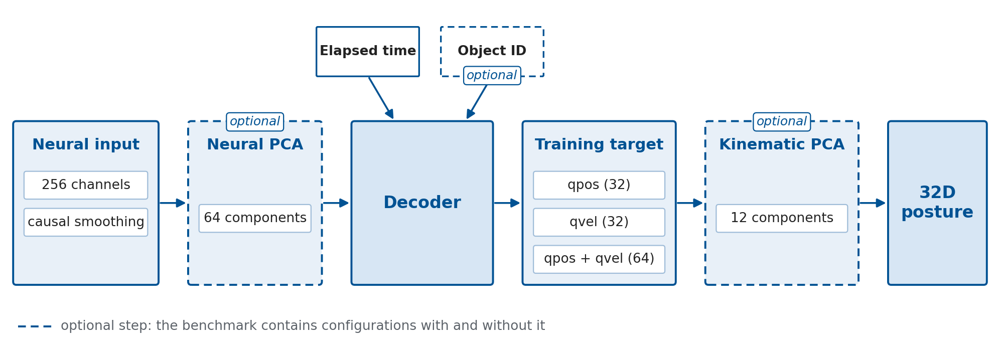

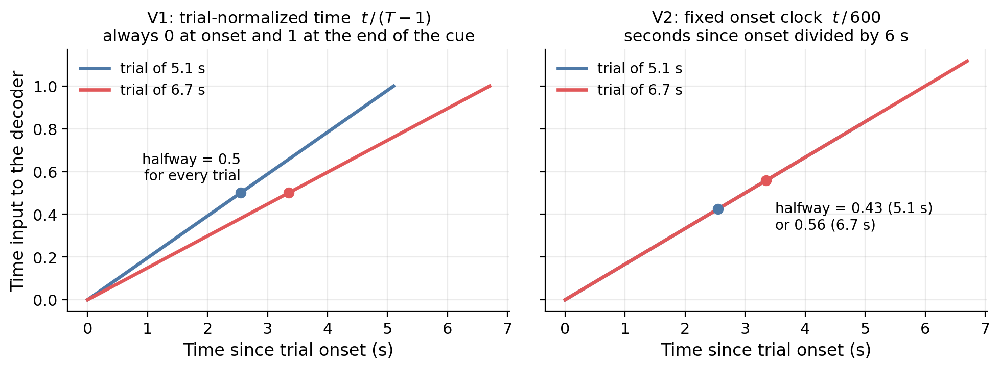

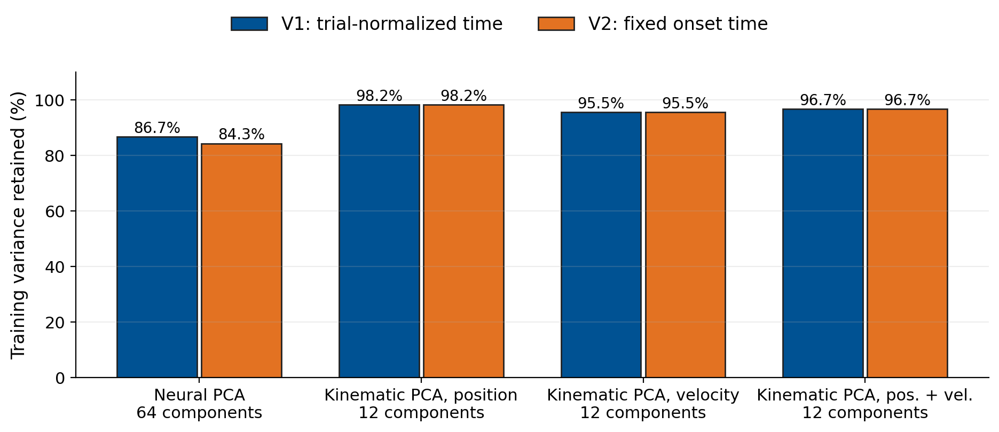

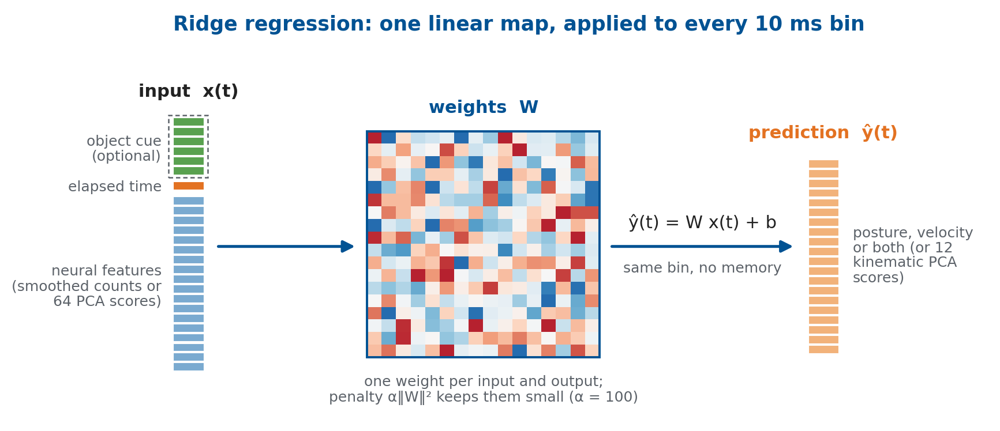

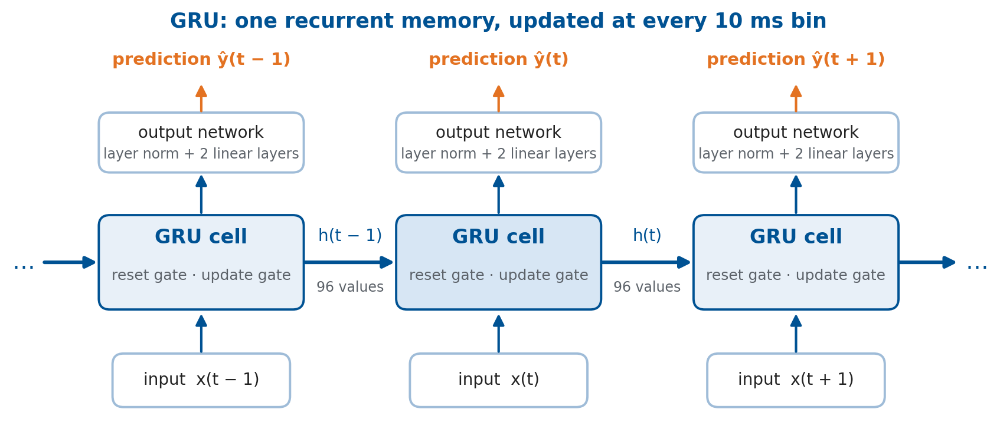

In [9]:
pipeline(FIGURES)
timing(FIGURES)
pca_variance(runs, FIGURES)
ridge(FIGURES)
gru(FIGURES)

### 4.3 Training (commented out) and loading the trained models
Training reruns the complete benchmark of a run (all holdouts, decoder families, object-cue, PCA and target conditions; several hundred models). It needs the recordings at `RECORDINGS`, takes more than a day on a CPU, and writes into a new folder, so that the saved results are never overwritten. **The training commands are commented out on purpose**; the trained models are loaded from disk directly below.

**How the training is started.** The training code of each run is a separate program in `run_v1/functions` and `run_v2/functions`, started from a terminal on the training machine. The notebook starts exactly these programs with `subprocess.run`: Python's standard way of running a terminal command and waiting until it has finished (a *subprocess* is a program started by another program, here by the notebook). `shell=True` lets the command be written as in a terminal, `check=True` stops the notebook with an error if the training fails, and `env` makes `python` inside the commands refer to the Python of this notebook's environment. To retrain, for example on the Ubuntu machine that holds the recordings, set `RECORDINGS` to their folder (or link them into `data/patient_sessions`) and remove the `#` in front of the two `subprocess.run` lines. With `TRAINING_PROFILE = 'smoke'`, each run trains only a few models on the repeat holdout, which checks the whole pipeline within minutes. Both commands were tested this way on a synthetic copy of the recordings.

In [10]:
# --- Training (remove the # in front of subprocess.run to retrain; requires the recordings) -------------
data = Path(RECORDINGS).expanduser()                               # relative to the repository root, or absolute
data_v1 = data if data.is_absolute() else Path('../..') / data      # the V1 command runs inside run_v1/functions
env = dict(os.environ, PATH=os.path.dirname(sys.executable) + os.pathsep + os.environ['PATH'])
train_v1 = (f'cd run_v1/functions && THESIS_VM_DATA_ROOT="{data_v1}" THESIS_SESSION_HOLDOUT_TEST_DATE=20260707 '
            f'bash run_strict_same_thresholds_suite.sh {TRAINING_PROFILE} auto')
train_v2 = (f'python run_v2/functions/run_final.py {TRAINING_PROFILE} --data-root "{data}" '
            f'--output-root {NEW_TRAINING} --device cpu')
print('V1 training command:', train_v1)
print('V2 training command:', train_v2)
# subprocess.run(train_v1, shell=True, check=True, env=env)   # V1: trial-normalized time -> run_v1/functions/vm_results/
# subprocess.run(train_v2, shell=True, check=True, env=env)   # V2: fixed onset clock -> new_training_results/

# --- Load the trained models from disk -------------------------------------------------------------
loaded = {}
for name, r in runs.items():
    for object_id in (True, False):
        row = candidate(r, object_id)
        model, payload = models.load_decoder(ROOT, name, row.experiment_id)
        loaded[(name, object_id)] = model
        print(f'{name.upper()} | object ID: {object_id!s:5} | {describe(row)} | '
              f'{sum(p.numel() for p in model.parameters()):,} parameters')
for name in runs:
    print(f'{name.upper()}: {len(models.checkpoint_inventory(ROOT, name))} saved model folders')

# Configurations evaluated per holdout in each run
display(pd.DataFrame({name: r['board'].groupby('split_mode').size() for name, r in runs.items()}))

V1 training command: cd run_v1/functions && THESIS_VM_DATA_ROOT="../../data/patient_sessions" THESIS_SESSION_HOLDOUT_TEST_DATE=20260707 bash run_strict_same_thresholds_suite.sh full auto
V2 training command: python run_v2/functions/run_final.py full --data-root "data/patient_sessions" --output-root new_training_results --device cpu


V1 | object ID: True  | GRU, object ID, neural PCA64, position target, no kinematic PCA | 61,280 parameters


V1 | object ID: False | GRU, no object ID, neural PCA64, position + velocity target, no kinematic PCA | 62,656 parameters


V2 | object ID: True  | LFADS-lite, object ID, neural PCA64, position target, kinematic PCA12 | 58,643 parameters


V2 | object ID: False | GRU, no object ID, neural PCA64, position target, no kinematic PCA | 59,552 parameters
V1: 288 saved model folders
V2: 480 saved model folders


,v1,v2
split_mode,,
block_holdout,108,120
gesture_holdout,108,120
repeat_holdout,108,120
session_holdout,108,120


## 5. Research question — primary target: posture (thesis Chapter 5)
**Question.** How accurately can patient-specific decoders predict the continuous 32-coordinate arm-and-hand posture from intracortical activity during attempted reach-and-grasp movements, and how does this depend on the decoder family, the object cue, neural and kinematic PCA, and the relation between training and test movements?

**Method.** Ridge, Kalman, ReFIT-style Kalman, GRU, LFADS-lite and Transformer decoders, each with and without object ID and with and without neural PCA (64) and kinematic PCA (12), evaluated on four holdouts: new repetitions of known movements (repeat), movements never seen during training (gesture), a later recording day (session) and a held-out block (block). Configurations are selected on the validation posture R²; the pooled test R², CC, RMSE, shape similarity and computation time are reported.

### 5.1 Plotting and table functions of Chapter 5

In [11]:
# Results figures of Chapter 5
def _scatter_panel(ax, rows, score, title):
    """Points for every family/cue configuration; the highest test score of each holdout is ringed and labelled."""
    xpos = lambda r: SPLITS.index(r.split_mode) + (DIRECT.index(r.model_family) - 1.5) * .14 + (.03 if r.condition_object else -.03)
    for _, r in rows.iterrows():
        ax.scatter(xpos(r), r[score], color=FAMILY_COLOR[r.model_family], marker='o' if r.condition_object else 's',
                   s=48, edgecolor='#222222', linewidth=.4, zorder=3)
    for i, split in enumerate(SPLITS):
        part = rows[rows.split_mode.eq(split)]
        best = part.sort_values(score, ascending=False).iloc[0]    # highest test score among the plotted points
        ax.scatter(xpos(best), best[score], s=190, facecolor='none', edgecolor='#111111', linewidth=1.4, zorder=4)
        ax.annotate(f'{FAMILY_LABEL[best.model_family]}\nR² = {best[score]:.2f}\n{pca_tag(best)}',
                    xy=(xpos(best), best[score]), xytext=(i, part[score].max() + .07), textcoords='data',
                    ha='center', va='bottom', fontsize=10, fontweight='bold',
                    bbox=dict(facecolor='white', edgecolor='none', alpha=.9, pad=1.5), zorder=5,
                    arrowprops=dict(arrowstyle='-', color='#333333', lw=.9, shrinkA=0, shrinkB=6))
    ax.set_xticks(range(4), [SPLIT_LONG[s] for s in SPLITS], fontsize=10)
    ax.axhline(0, color='#555555', lw=.8)
    ax.grid(axis='y', alpha=.2)
    ax.set_title(title, fontsize=12)
    ax.set_ylabel('Test R²')
    lo = min(0, float(rows[score].min()))
    ax.set_ylim(lo - .05, float(rows[score].max()) + .42)


def four_panel(r, out):
    """Posture after reconstruction plus the three raw training targets (one run)."""
    b = r['board'][r['board'].model_family.isin(DIRECT)]
    posture = select(b, ['split_mode', 'model_family', 'condition_object'])
    raw = select(b, ['split_mode', 'model_family', 'condition_object', 'target_base_mode'], 'val_R2')
    fig, axes = plt.subplots(2, 2, figsize=(10.5, 9.4))
    fig.subplots_adjust(left=.07, right=.99, top=.855, bottom=.07, hspace=.36, wspace=.2)
    _scatter_panel(axes[0, 0], posture, 'test_qpos_R2', 'Posture (qpos) after reconstruction')
    for ax, t in zip([axes[0, 1], axes[1, 0], axes[1, 1]], ['qpos', 'qvel', 'pv']):
        _scatter_panel(ax, raw[raw.target_base_mode.eq(t)], 'test_R2', f'{TARGET_LABEL[t]} (raw training target)')
    handles = [Line2D([], [], marker='o', ls='', color=FAMILY_COLOR[m], markeredgecolor='#222', label=FAMILY_LABEL[m]) for m in DIRECT]
    handles += [Line2D([], [], marker=m, ls='', color='#555555', label=l) for m, l in [('o', 'With object ID'), ('s', 'Without object ID')]]
    fig.legend(handles=handles, loc='upper center', ncol=6, bbox_to_anchor=(.5, .968), frameon=False, fontsize=10, columnspacing=1.0, handletextpad=.3)
    fig.text(.5, .9, 'Ringed point and label: highest test score of each holdout in the panel.\n'
             'N64 / N0: with / without neural PCA;  K12 / K0: with / without kinematic PCA.', ha='center', fontsize=10.5, color='#444444')
    fig.suptitle(RUN_TITLE[r['run']] + ' — direct decoder performance', y=.995, fontsize=14, fontweight='bold')
    return save(fig, out, f"{r['run']}_four_panel_summary", pd.concat([posture.assign(panel='posture'), raw.assign(panel='raw')]))


def run_comparison(runs, out):
    """Validation-selected posture score per split, V1 next to V2."""
    rows = []
    for name, r in runs.items():
        for split in SPLITS:
            best = select(r['board'][r['board'].split_mode.eq(split)], ['split_mode']).iloc[0]
            rows.append(dict(run=name, split=split, model=FAMILY_LABEL[best.model_family], tag=pca_tag(best),
                             object_id=best.condition_object, test_qpos_R2=best.test_qpos_R2,
                             experiment_id=best.experiment_id))
    data = pd.DataFrame(rows)
    fig, ax = plt.subplots(figsize=(9, 4.6))
    fig.subplots_adjust(left=.09, right=.99, top=.85, bottom=.15)
    x = np.arange(4)
    for k, name in enumerate(['v1', 'v2']):
        part = data[data.run.eq(name)].set_index('split').reindex(SPLITS)
        bars = ax.bar(x + (k - .5) * .38, part.test_qpos_R2, width=.36, color=RUN_COLOR[name],
                      edgecolor='#222222', lw=.6, label=RUN_TITLE[name])
        for bar, (_, p) in zip(bars, part.iterrows()):
            ax.text(bar.get_x() + bar.get_width() / 2, p.test_qpos_R2 + .015, f'{p.test_qpos_R2:.2f}\n{p.model}',
                    ha='center', va='bottom', fontsize=9.5)
    ax.set_xticks(x, [SPLIT_LONG[s] for s in SPLITS])
    ax.set_ylim(0, 1.05)
    ax.set_ylabel('Test posture R² (validation-selected)')
    ax.grid(axis='y', alpha=.22)
    fig.legend(*ax.get_legend_handles_labels(), loc='upper center', ncol=2, frameon=False, fontsize=12)
    return save(fig, out, 'run_comparison', data)


def model_families(runs, out):
    """All six families per split; Kalman-family errors on a separate lower scale."""
    frames = []
    fig, axes = plt.subplots(2, 2, figsize=(10, 7), sharex=True, gridspec_kw={'height_ratios': [2.2, 1]})
    fig.subplots_adjust(left=.07, right=.99, top=.86, bottom=.08, hspace=.12, wspace=.16)
    for col, (name, r) in enumerate(runs.items()):
        best = select(r['board'], ['split_mode', 'model_family'])
        frames.append(best.assign(run=name))
        for ax, fams in zip(axes[:, col], [DIRECT, ['kalman', 'refit_kalman']]):
            for j, fam in enumerate(fams):
                part = best[best.model_family.eq(fam)].set_index('split_mode').reindex(SPLITS)
                ax.plot(np.arange(4) + (j - (len(fams) - 1) / 2) * .05, part.test_qpos_R2, marker='o', lw=1.4,
                        ms=7, color=FAMILY_COLOR[fam], label=FAMILY_LABEL[fam])
            ax.axhline(0, color='#555555', lw=.8)
            ax.grid(axis='y', alpha=.22)
        axes[0, col].set_ylim(0, 1)
        axes[1, col].set_ylim(-9, .5)
        axes[0, col].set_title(RUN_TITLE[name], fontsize=14, fontweight='bold')
        axes[1, col].set_xticks(range(4), [SPLIT_LONG[s] for s in SPLITS], fontsize=10.5)
    axes[0, 0].set_ylabel('Test posture R²')
    axes[1, 0].set_ylabel('Test posture R²\n(Kalman family)')
    handles = [Line2D([], [], marker='o', color=FAMILY_COLOR[m], label=FAMILY_LABEL[m]) for m in DIRECT + ['kalman', 'refit_kalman']]
    fig.legend(handles=handles, loc='upper center', ncol=3, frameon=False, fontsize=11)
    fig.subplots_adjust(top=.82)
    return save(fig, out, 'model_families_paired', pd.concat(frames))


def object_context(runs, out):
    """Repeat holdout: each family with and without object ID (dumbbell plot)."""
    frames = []
    fig, axes = plt.subplots(1, 2, figsize=(10, 4.2), sharey=True)
    fig.subplots_adjust(left=.12, right=.98, top=.78, bottom=.15, wspace=.12)
    for ax, (name, r) in zip(axes, runs.items()):
        b = r['board'][r['board'].split_mode.eq('repeat_holdout') & r['board'].model_family.isin(DIRECT)]
        best = select(b, ['model_family', 'condition_object'])
        frames.append(best.assign(run=name))
        for i, fam in enumerate(DIRECT):
            p = best[best.model_family.eq(fam)].set_index('condition_object')
            a, c = float(p.loc[False, 'test_qpos_R2']), float(p.loc[True, 'test_qpos_R2'])
            ax.plot([a, c], [i, i], color='#c3c8cc', lw=4, zorder=1)
            ax.scatter(a, i, s=120, marker='s', color=RAW_GREY, edgecolor='#222', zorder=2, label='Without object ID' if i == 0 else None)
            ax.scatter(c, i, s=120, color=FAMILY_COLOR[fam], edgecolor='#222', zorder=2, label='With object ID' if i == 0 else None)
            ax.text(a - .02, i, f'{a:.2f}', ha='right', va='center', fontsize=11)
            ax.text(c + .02, i, f'{c:.2f}', ha='left', va='center', fontsize=11)
        ax.set_yticks(range(4), [FAMILY_LABEL[m] for m in DIRECT])
        ax.set_xlim(0, 1)
        ax.set_ylim(3.6, -.6)
        ax.set_xlabel('Test posture R² (repeat holdout)')
        ax.grid(axis='x', alpha=.22)
        ax.set_title(RUN_TITLE[name], fontsize=14, fontweight='bold')
    handles = [Line2D([], [], marker='s', ls='', color=RAW_GREY, markeredgecolor='#222', ms=10, label='Without object ID'),
               Line2D([], [], marker='o', ls='', color='#555555', markeredgecolor='#222', ms=10, label='With object ID (family colour)')]
    fig.legend(handles=handles, loc='upper center', ncol=2, frameon=False, fontsize=12)
    return save(fig, out, 'object_context_paired', pd.concat(frames))


def object_wise(runs, out):
    """Trial mean ± SD of posture R² per object for the object-conditioned candidate of each run."""
    frames = []
    fig, axes = plt.subplots(1, 2, figsize=(10, 5), sharey=True)
    fig.subplots_adjust(left=.09, right=.99, top=.86, bottom=.27, wspace=.08)
    for ax, (name, r) in zip(axes, runs.items()):
        row = candidate(r, True)
        g = test_trials(r, row).groupby('object_name').qpos_R2.agg(['mean', 'std', 'size']).reindex(OBJECTS)
        frames.append(g.reset_index().assign(run=name, experiment_id=row.experiment_id))
        ax.bar(range(6), g['mean'], yerr=g['std'], capsize=4, color=[OBJECT_COLOR[o] for o in OBJECTS],
               edgecolor='#222', lw=.7)
        for i, (m, sd) in enumerate(zip(g['mean'], g['std'])):
            ax.text(i, m + sd + .04, f'{m:.2f}', ha='center', va='bottom', fontsize=10, fontweight='bold')
        ax.set_xticks(range(6), [OBJECT_LABEL[o] for o in OBJECTS], rotation=35, ha='right', fontsize=10)
        ax.axhline(0, color='#555', lw=.8)
        ax.grid(axis='y', alpha=.22)
        ax.set_title(f"{RUN_TITLE[name]}\n{FAMILY_LABEL[row.model_family]} with object ID", fontsize=13)
    axes[0].set_ylabel('Posture R² per test trial (mean ± SD)')
    axes[0].set_ylim(-1, 1.45)
    return save(fig, out, 'object_wise_paired', pd.concat(frames))


def coordinate_label(name):
    """Readable coordinate name, e.g. 'T_MCP_flexion' -> 'Thumb MCP flexion'."""
    head, _, rest = name.partition('_')
    head = {'T': 'Thumb', 'I': 'Index', 'M': 'Middle'}.get(head, head)
    return (head + ' ' + rest.replace('_', ' ')).strip()


def joint_r2(runs, out, object_id=True):
    """Pooled posture R² of every coordinate, V1 above V2, coloured by limb."""
    frames = []
    fig, axes = plt.subplots(2, 1, figsize=(10, 11))
    fig.subplots_adjust(left=.08, right=.99, bottom=.12, top=.88, hspace=.75)   # top margin keeps the legend clear of the first title
    for ax, (name, r) in zip(axes, runs.items()):
        row = candidate(r, object_id)
        d = r['joints'][r['joints'].experiment_id.eq(row.experiment_id) & r['joints'].space.eq('qpos_replay')].sort_values('dimension')
        groups = d.dimension_name.map(limb)
        ax.bar(d.dimension, d.R2, color=[LIMB_COLOR[g] for g in groups], edgecolor='#222', lw=.45)
        ax.set_xticks(d.dimension, [coordinate_label(n) for n in d.dimension_name], rotation=90, fontsize=9.5)
        ax.set_title(f"{RUN_TITLE[name]}\n{describe(row)}", fontsize=11.5)
        ax.set_ylabel('Test R² per coordinate')
        ax.axhline(0, color='#555', lw=.8)
        ax.grid(axis='y', alpha=.22)
        ax.set_ylim(min(-.05, float(d.R2.min()) - .05), 1)
        frames.append(d.assign(run=name))
    fig.legend(handles=[Patch(color=c, label=g) for g, c in LIMB_COLOR.items()], loc='upper center',
               bbox_to_anchor=(.5, .995), ncol=8, frameon=False, fontsize=10.5, handlelength=1.2, columnspacing=1.1)
    suffix = 'object_id' if object_id else 'no_object_id'
    return save(fig, out, f'joint_r2_{suffix}_paired', pd.concat(frames))

In [12]:
# Tables (written as CSV and LaTeX)
def _write(table, out, name, column_format=None):
    out = Path(out)
    out.mkdir(parents=True, exist_ok=True)
    table.to_csv(out / f'{name}.csv', index=False)
    latex = table.to_latex(index=False, escape=False, column_format=column_format, float_format='%.3f')
    (out / f'{name}.tex').write_text(latex.replace('R2', '$R^2$'))
    return table


def _config(row):
    """Model plus a compact description of its PCA setting and target."""
    target = {'qpos': 'pos.', 'qvel': 'vel.', 'pv': 'pos.+vel.'}[row.target_base_mode]
    return f'{FAMILY_LABEL[row.model_family]} ({pca_tag(row)}, {target})'


def _metrics(row):
    return {'R2': row.test_qpos_R2, 'CC': row.test_qpos_CC, 'RMSE (rad)': row.test_qpos_RMSE,
            'Shape': row.test_qpos_procrustes_corr, 'Latency (ms/bin)': row.latency_ms_per_bin_offline}


def candidates(runs, out):
    """Repeat-holdout candidates of both runs, with and without object ID."""
    rows = []
    for name, r in runs.items():
        for cue in (True, False):
            row = candidate(r, cue)
            rows.append({'Run': name.upper(), 'Object ID': 'yes' if cue else 'no', 'Configuration': _config(row), **_metrics(row)})
    return _write(pd.DataFrame(rows), out, 'repeat_candidates', 'lllrrrrr')


def splits(r, out):
    """Validation-selected posture configuration for each holdout split (one run)."""
    rows = []
    for split in SPLITS:
        row = select(r['board'][r['board'].split_mode.eq(split)], ['split_mode']).iloc[0]
        rows.append({'Holdout': SPLIT_SHORT[split], 'Object ID': 'yes' if row.condition_object else 'no',
                     'Configuration': _config(row), **_metrics(row)})
    return _write(pd.DataFrame(rows), out, f"{r['run']}_split_scores", 'lllrrrrr')

### 5.2 Results

,Run,Object ID,Configuration,R2,CC,RMSE (rad),Shape,Latency (ms/bin)
0,V1,yes,"GRU (N64 / K0, pos.)",0.832,0.911,0.084,0.945,0.010
1,V1,no,"GRU (N64 / K0, pos.+vel.)",0.544,0.722,0.141,0.833,0.011
2,V2,yes,"LFADS-lite (N64 / K12, pos.)",0.723,0.850,0.111,0.902,0.013
3,V2,no,"GRU (N64 / K0, pos.)",0.446,0.670,0.163,0.774,0.012


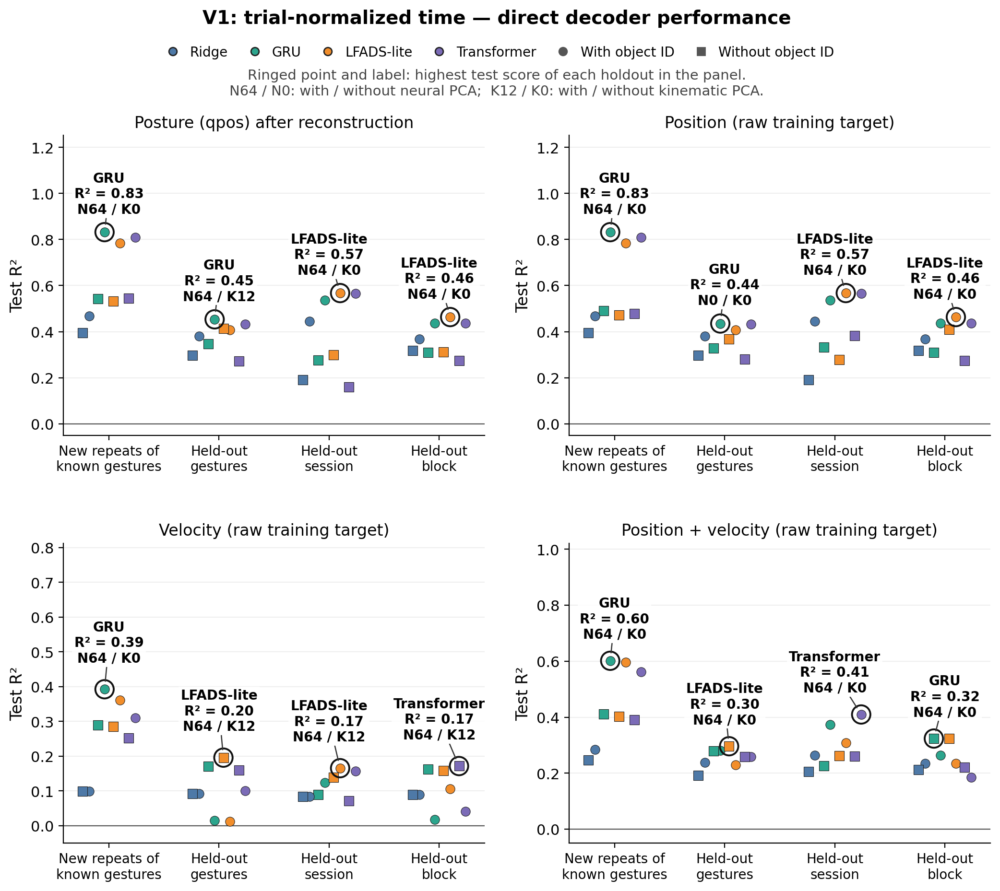

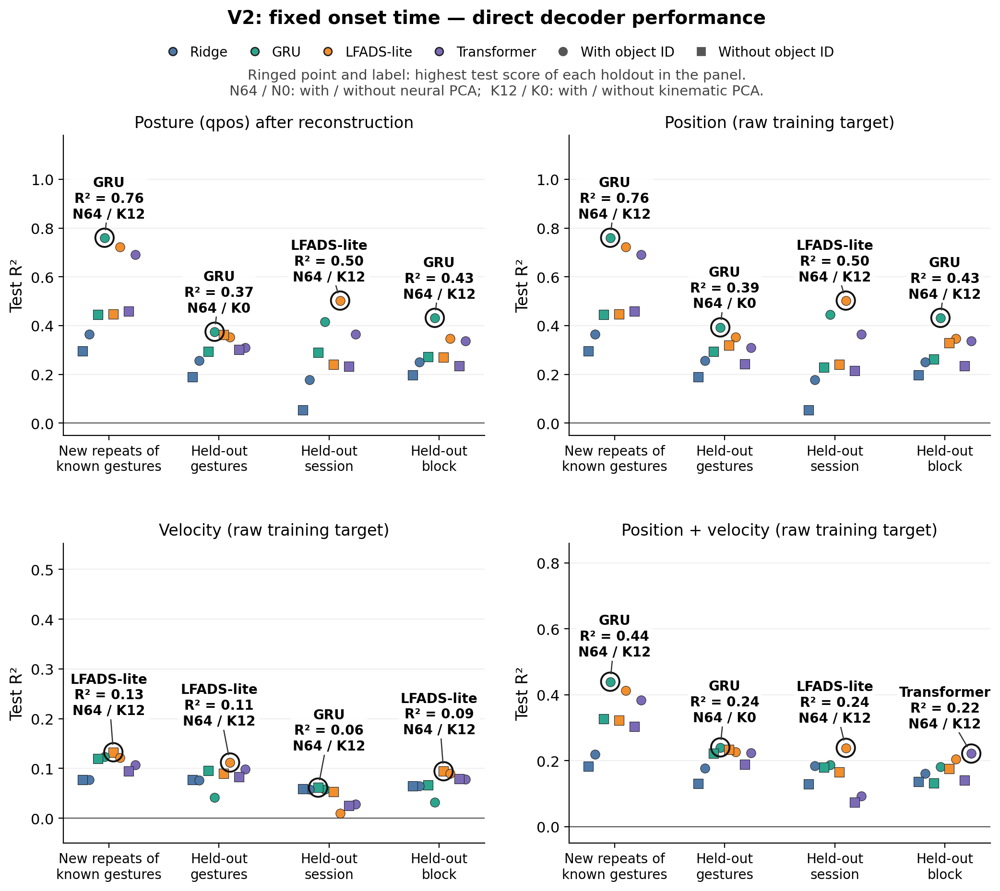

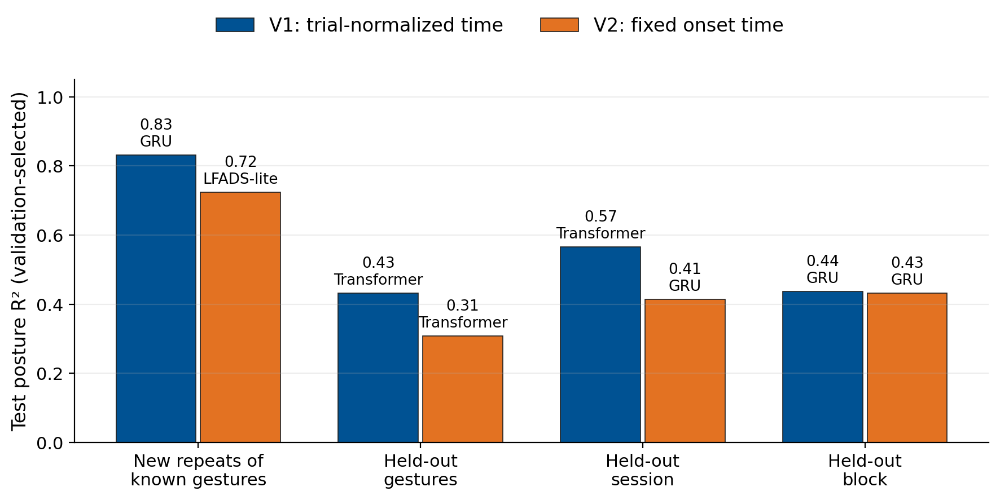

In [13]:
# Overview of each run, the selected candidates and the comparison between the runs
for name, r in runs.items():
    four_panel(r, FIGURES)
display(candidates(runs, TABLES).round(3))
run_comparison(runs, FIGURES)

**V1: trial-normalized time: validation-selected posture configuration per holdout**

,Holdout,Object ID,Configuration,R2,CC,RMSE (rad),Shape,Latency (ms/bin)
0,Repeat,yes,"GRU (N64 / K0, pos.)",0.832,0.911,0.084,0.945,0.010
1,Gesture,yes,"Transformer (N0 / K0, pos.+vel.)",0.432,0.708,0.149,0.826,0.008
2,Session,yes,"Transformer (N64 / K0, pos.)",0.565,0.771,0.133,0.861,0.010
3,Block,yes,"GRU (N64 / K0, pos.)",0.436,0.717,0.148,0.827,0.010


**V2: fixed onset time: validation-selected posture configuration per holdout**

,Holdout,Object ID,Configuration,R2,CC,RMSE (rad),Shape,Latency (ms/bin)
0,Repeat,yes,"LFADS-lite (N64 / K12, pos.)",0.723,0.850,0.111,0.902,0.013
1,Gesture,yes,"Transformer (N0 / K12, pos.)",0.309,0.623,0.175,0.746,0.015
2,Session,yes,"GRU (N64 / K12, pos.+vel.)",0.415,0.659,0.174,0.742,0.013
3,Block,yes,"GRU (N64 / K12, pos.)",0.432,0.706,0.152,0.811,0.012


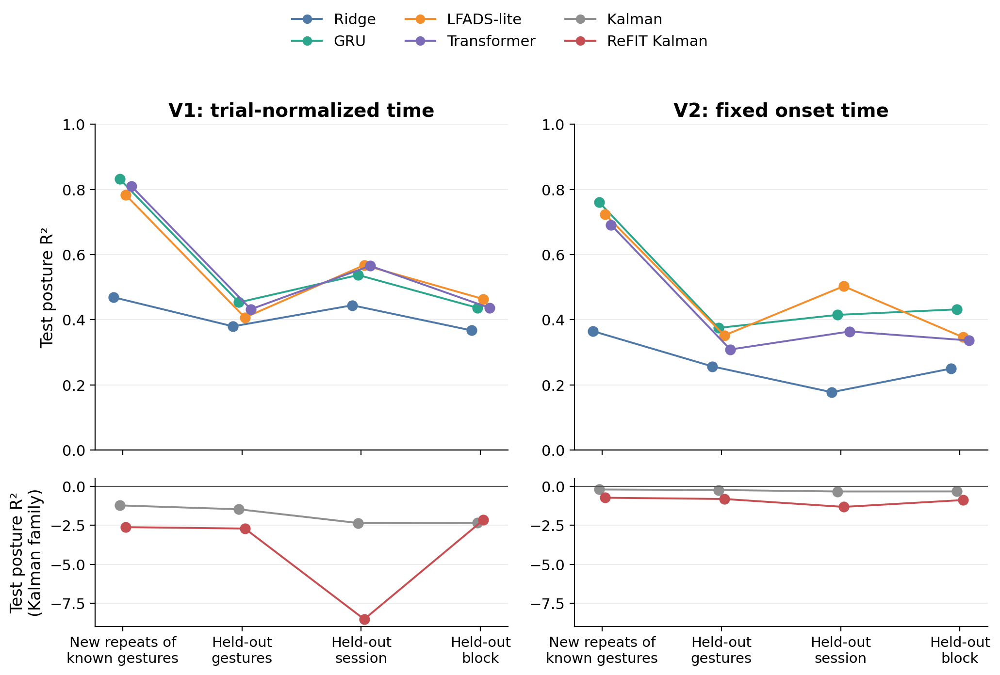

In [14]:
# Generalization across holdouts and decoder families
model_families(runs, FIGURES)
for name, r in runs.items():
    display(Markdown(f'**{RUN_TITLE[name]}: validation-selected posture configuration per holdout**'))
    display(splits(r, TABLES).round(3))

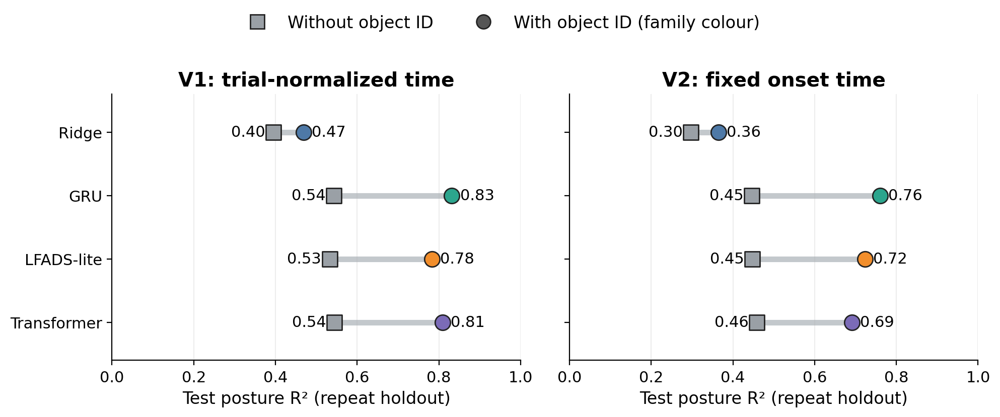

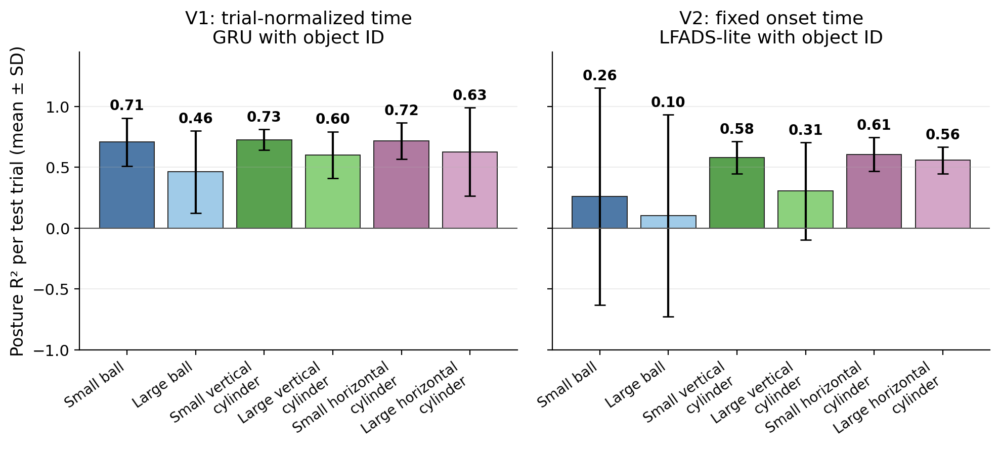

In [15]:
# Object context and object-wise accuracy
object_context(runs, FIGURES)
object_wise(runs, FIGURES)

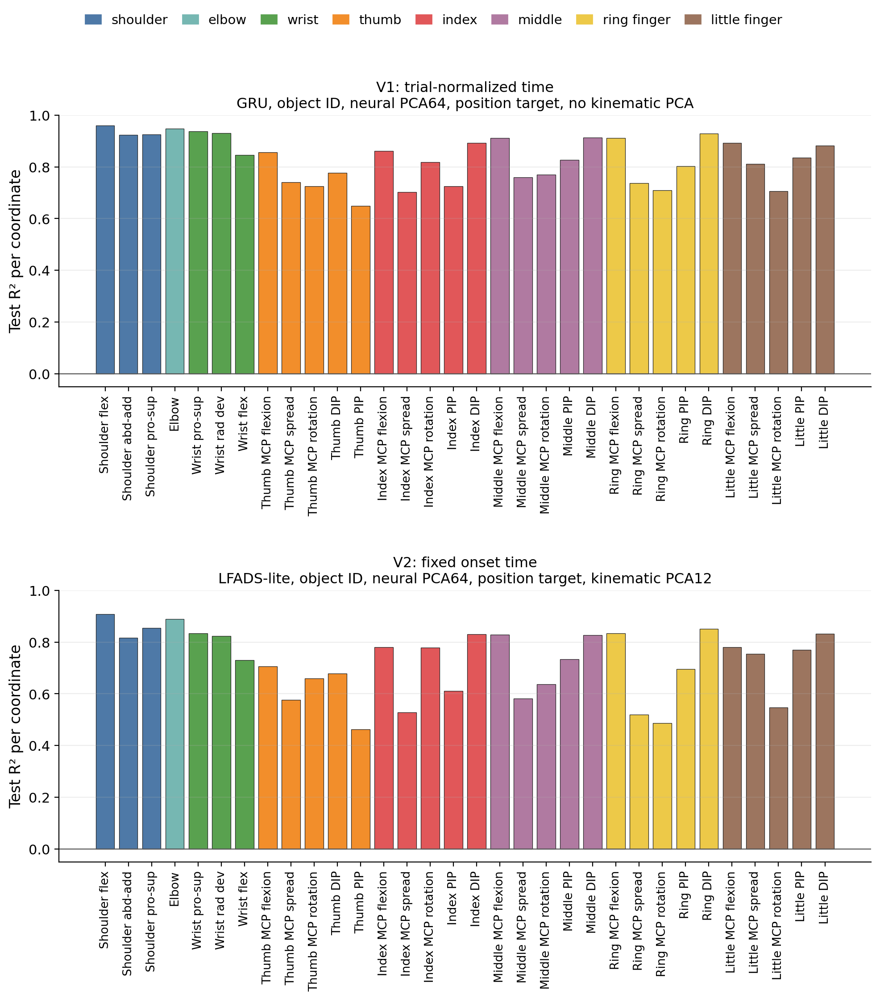

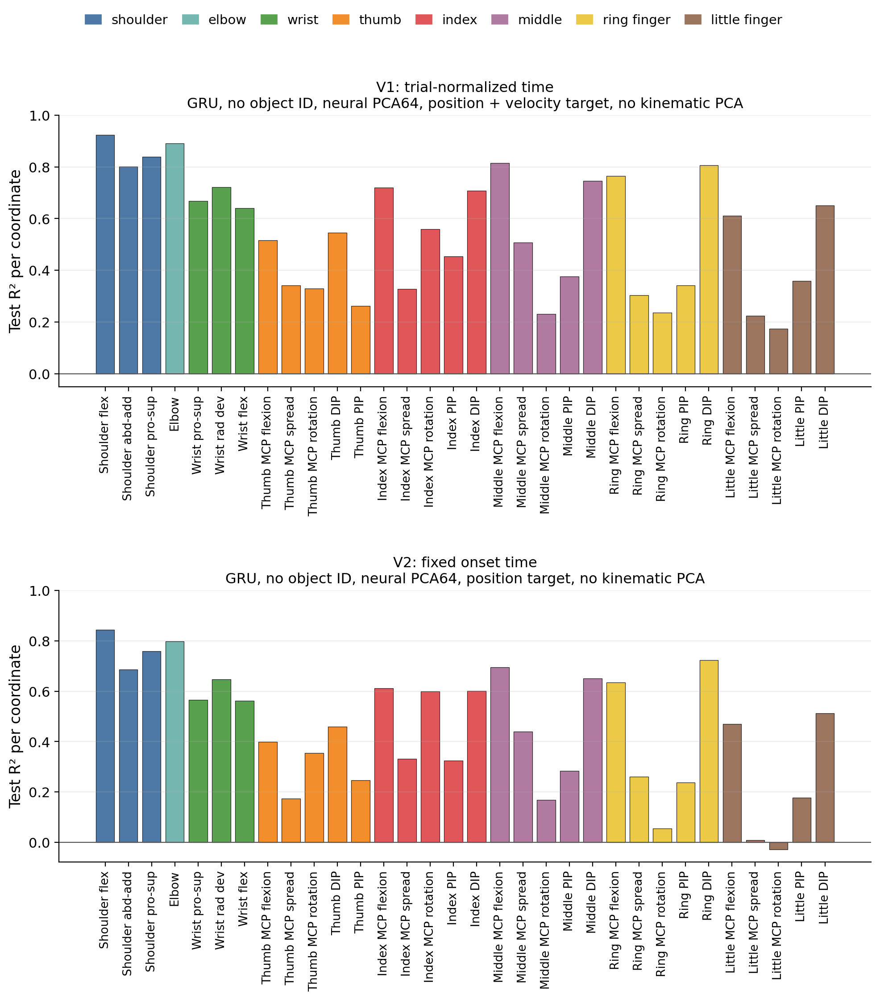

In [16]:
# Accuracy of individual joints, with and without object ID
joint_r2(runs, FIGURES, object_id=True)
joint_r2(runs, FIGURES, object_id=False)

**Answer.** On new repetitions of known movements, the object-conditioned GRU of V1 reconstructs the posture with R² = 0.832, CC = 0.911, RMSE = 0.084 rad and a shape similarity of 0.945; with the fixed onset clock of V2, the best decoder is an object-conditioned LFADS-lite with R² = 0.723. The recurrent and attention-based decoders clearly outperform Ridge, and the Kalman-family decoders remain below zero. The accuracy drops for movement trajectories that were never seen during training (gesture and block holdouts, R² 0.31–0.44) and for a later recording day (0.42–0.57). The object cue raises the R² of every nonlinear decoder by 0.23–0.31 on new repetitions, and the shoulder and elbow are reconstructed more accurately than the thumb and the fingers.

## 6. Secondary target: velocity (`qvel`)
**Question.** Can the same decoders predict the 32 joint velocities?

**Method.** The same grid trained on `qvel`; scores on the velocity itself for the configuration selected on validation, per holdout (lower-left panels of the overview figures in Section 5).

In [17]:
# Table of the raw training targets
def raw_targets(r, out):
    """Validation-selected configuration per target and split, scored on the raw training target."""
    rows = []
    for target in ['qpos', 'qvel', 'pv']:
        for split in SPLITS:
            part = r['board'][r['board'].split_mode.eq(split) & r['board'].target_base_mode.eq(target)]
            row = select(part, ['split_mode'], 'val_R2').iloc[0]
            rows.append({'Target': TARGET_LABEL[target], 'Holdout': SPLIT_SHORT[split], 'Configuration': _config(row),
                         'R2': row.test_R2, 'CC': row.test_CC, 'RMSE': row.test_RMSE})
    return _write(pd.DataFrame(rows), out, f"{r['run']}_raw_targets", 'lllrrr')

In [18]:
for name, r in runs.items():
    raw = raw_targets(r, TABLES)
    display(Markdown(f'**{RUN_TITLE[name]}**'))
    display(raw[raw.Target.eq('Velocity')].round(3))

**V1: trial-normalized time**

,Target,Holdout,Configuration,R2,CC,RMSE
4,Velocity,Repeat,"GRU (N64 / K0, vel.)",0.393,0.643,0.033
5,Velocity,Gesture,"LFADS-lite (N64 / K0, vel.)",0.013,0.404,0.042
6,Velocity,Session,"GRU (N64 / K12, vel.)",0.124,0.436,0.040
7,Velocity,Block,"GRU (N64 / K12, vel.)",0.018,0.420,0.041


**V2: fixed onset time**

,Target,Holdout,Configuration,R2,CC,RMSE
4,Velocity,Repeat,"LFADS-lite (N64 / K12, vel.)",0.133,0.348,0.040
5,Velocity,Gesture,"LFADS-lite (N64 / K12, vel.)",0.112,0.333,0.040
6,Velocity,Session,"LFADS-lite (N64 / K12, vel.)",0.010,0.262,0.044
7,Velocity,Block,"LFADS-lite (N64 / K12, vel.)",0.094,0.301,0.041


**Answer.** Velocity is much harder to predict than posture: the best velocity decoders reach R² = 0.39 (V1) and 0.13 (V2) on new repetitions, and below 0.13 on the other holdouts.

## 7. Secondary target: position + velocity (`qpos` + `qvel`)
**Question.** Does a combined 64-value target, in which the velocity acts as an additional training signal, improve the decoding?

**Method.** The same grid trained on positions and velocities together; scores on the combined target for the configuration selected on validation, per holdout.

In [19]:
for name, r in runs.items():
    raw = raw_targets(r, TABLES)
    display(Markdown(f'**{RUN_TITLE[name]}**'))
    display(raw[raw.Target.eq('Position + velocity')].round(3))

**V1: trial-normalized time**

,Target,Holdout,Configuration,R2,CC,RMSE
8,Position + velocity,Repeat,"GRU (N64 / K0, pos.+vel.)",0.602,0.777,0.072
9,Position + velocity,Gesture,"LFADS-lite (N64 / K0, pos.+vel.)",0.229,0.563,0.108
10,Position + velocity,Session,"GRU (N64 / K0, pos.+vel.)",0.374,0.647,0.099
11,Position + velocity,Block,"GRU (N64 / K0, pos.+vel.)",0.263,0.602,0.106


**V2: fixed onset time**

,Target,Holdout,Configuration,R2,CC,RMSE
8,Position + velocity,Repeat,"LFADS-lite (N64 / K0, pos.+vel.)",0.412,0.652,0.094
9,Position + velocity,Gesture,"GRU (N64 / K0, pos.+vel.)",0.240,0.502,0.119
10,Position + velocity,Session,"GRU (N64 / K12, pos.+vel.)",0.188,0.474,0.127
11,Position + velocity,Block,"GRU (N64 / K0, pos.+vel.)",0.182,0.543,0.115


**Answer.** The combined target reaches intermediate values (R² = 0.60 in V1 and 0.41 in V2 on new repetitions), because its score averages an easier position part and a harder velocity part. It is occasionally selected for the posture, but it gives no consistent advantage over the direct posture target, which remains the most reliable target.

## 8. Input perturbations and training behaviour (thesis Chapter 5)
**Method.** The selected object-conditioned decoder of each run is evaluated twice more on the test trials with its trained weights unchanged: once with random numbers (with the mean and spread of the real recordings) in place of the neural activity, and once with a randomly chosen wrong object ID. The training and validation losses show which epoch was kept by early stopping.

In [20]:
# Figures of the perturbation controls and the training curves
def perturbations(runs, out):
    """Same trained candidate evaluated with real inputs, Gaussian neural input and a wrong object ID."""
    rows = []
    for name, r in runs.items():
        row = candidate(r, True)
        for label, col in [('Real inputs', 'test_qpos_R2'), ('Gaussian noise\ninstead of neural input', 'test_random_neural_qpos_R2'),
                           ('Wrong object ID', 'test_random_object_qpos_R2')]:
            rows.append(dict(run=name, condition=label, R2=float(row[col]), experiment_id=row.experiment_id,
                             model=FAMILY_LABEL[row.model_family]))
    data = pd.DataFrame(rows)
    conditions = list(dict.fromkeys(data.condition))
    colors = ['#2ca58d', '#9aa0a6', '#c44e52']
    fig, axes = plt.subplots(1, 2, figsize=(10, 4.4), sharey=True)
    fig.subplots_adjust(left=.09, right=.99, top=.84, bottom=.2, wspace=.08)
    for ax, name in zip(axes, runs):
        part = data[data.run.eq(name)].set_index('condition').reindex(conditions)
        bars = ax.bar(range(3), part.R2, color=colors, edgecolor='#222', lw=.7, width=.6)
        for bar, v in zip(bars, part.R2):
            ax.text(bar.get_x() + bar.get_width() / 2, v + (.03 if v >= 0 else -.03), f'{v:.2f}',
                    ha='center', va='bottom' if v >= 0 else 'top', fontsize=12)
        ax.set_xticks(range(3), conditions, fontsize=10)
        ax.axhline(0, color='#333', lw=.9)
        ax.grid(axis='y', alpha=.22)
        ax.set_title(f"{RUN_TITLE[name]}\n{part.model.iloc[0]} with object ID", fontsize=12)
    axes[0].set_ylabel('Test posture R²')
    axes[0].set_ylim(min(-.5, data.R2.min() - .15), 1)
    return save(fig, out, 'input_perturbations_paired', data)


def training_curves(runs, out):
    """Training and validation objective of the two object-conditioned candidates."""
    frames = []
    fig, axes = plt.subplots(1, 2, figsize=(10, 4.6))
    fig.subplots_adjust(left=.08, right=.99, top=.78, bottom=.13, wspace=.22)
    for ax, (name, r) in zip(axes, runs.items()):
        row = candidate(r, True)
        h = r['history'][r['history'].experiment_id.eq(row.experiment_id)].sort_values('epoch')
        kept = int(row.best_epoch)
        ax.plot(h.epoch, h.train_loss, color='#4e79a7', lw=2, label='Training set')
        ax.plot(h.epoch, h.val_loss, color='#f28e2b', lw=2, label='Validation set')
        ax.axvline(kept, color='#555', ls='--', lw=1)
        ax.scatter(kept, h.set_index('epoch').loc[kept, 'val_loss'], color='#f28e2b', edgecolor='#222', s=70, zorder=5)
        ax.text(kept - 1, ax.get_ylim()[1] * .92, f'kept model:\nepoch {kept}', ha='right', va='top', fontsize=10.5)
        ax.set_xlabel('Training epoch')
        ax.set_ylabel('Loss (standardized units)')
        ax.grid(alpha=.2)
        ax.set_title(f"{RUN_TITLE[name]}\n{FAMILY_LABEL[row.model_family]} with object ID", fontsize=12)
        frames.append(h.assign(run=name))
    fig.legend(*axes[0].get_legend_handles_labels(), loc='upper center', ncol=2, frameon=False, fontsize=12)
    return save(fig, out, 'training_validation_paired', pd.concat(frames))

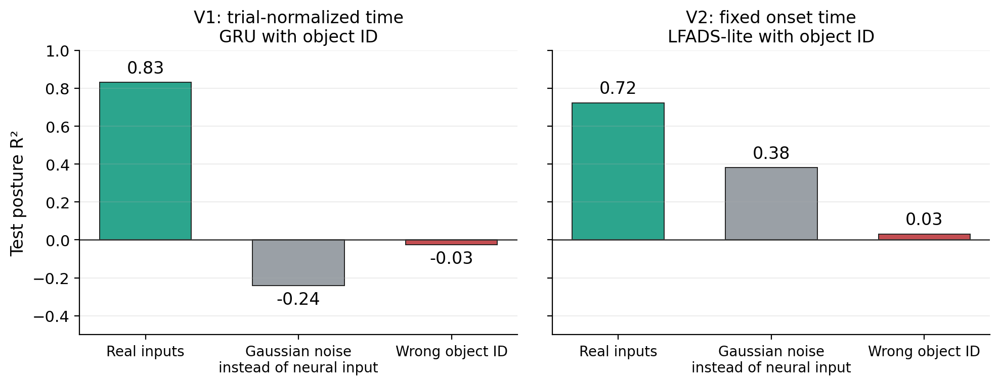

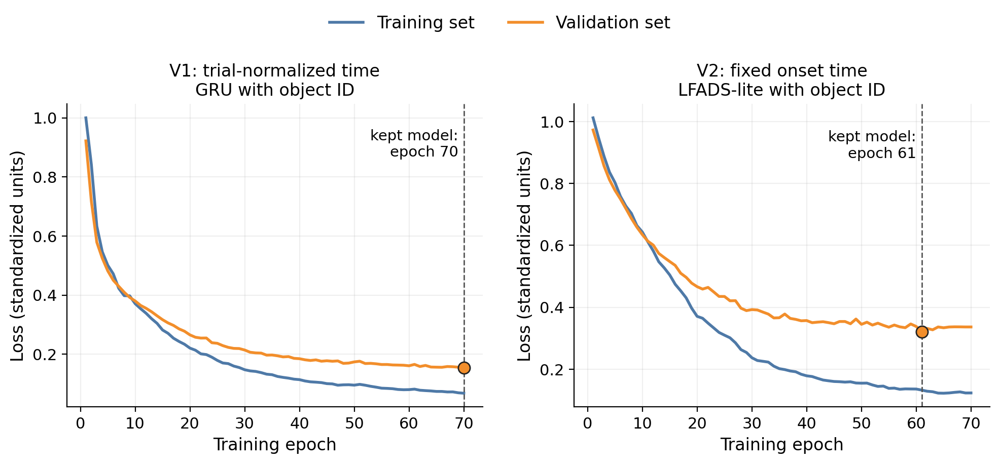

In [21]:
perturbations(runs, FIGURES)
training_curves(runs, FIGURES)

**Answer.** A wrong object ID breaks both decoders (R² −0.03 in V1 and 0.03 in V2). With random neural input, the V1 GRU collapses (R² −0.24), whereas the V2 LFADS-lite keeps R² = 0.38: with the fixed clock, the elapsed time and the object cue alone carry a considerable part of the posture, and the neural activity raises the accuracy from 0.38 to 0.72.

## 9. Simulation: reference and decoded movement of one held-out trial (thesis Chapter 6)
Select the held-out test trial with `SIM_DAY`, `SIM_BLOCK`, `SIM_TRIAL` and `SIM_REPETITION` in Section 2; the table lists every test trial with a saved replay. The reference posture and the decoded posture of the object-conditioned candidate are played through the same MuJoCo arm-and-hand model: still frames at rest, reach, grasp, hold and return, and an animation that shows the reference (left) and the decoded movement (right) next to each other in real time. The reference is the prescribed movement shown to the participant, not a measured limb movement. The MuJoCo replay functions are larger and live in `plotting_functions/simulation.py`.

**V1: trial-normalized time — GRU, object ID, neural PCA64, position target, no kinematic PCA**

,day-block,trial,repetition,object
0,20260630-block1,0,8,small_h_cylinder
1,20260630-block2,1,8,small_h_cylinder
2,20260630-block2,2,8,big_h_cylinder
3,20260630-block1,5,8,big_h_cylinder
4,20260630-block1,6,8,big_ball
5,20260630-block1,7,8,small_ball
6,20260630-block2,8,8,big_ball
7,20260630-block2,9,8,small_ball
8,20260630-block1,12,8,big_v_cylinder
9,20260630-block1,13,8,small_v_cylinder


Selected test trial: 20260630-block1, trial 12, repetition 9 of 10, object big_v_cylinder


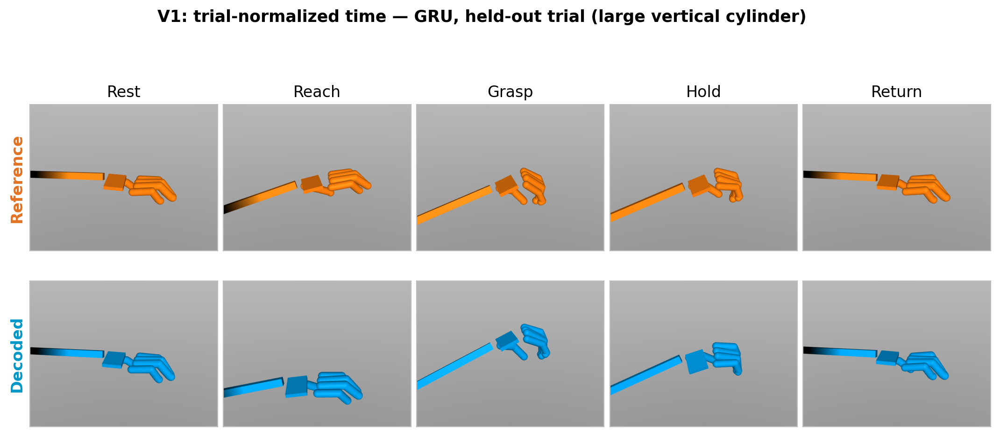

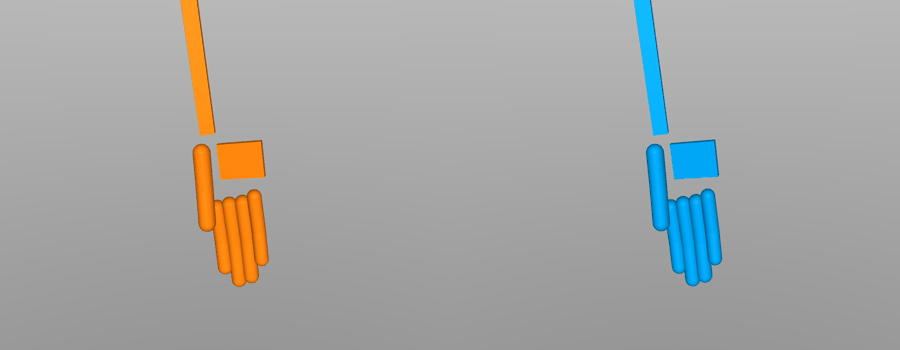

**V2: fixed onset time — LFADS-lite, object ID, neural PCA64, position target, kinematic PCA12**

,day-block,trial,repetition,object
0,20260630-block1,0,8,small_h_cylinder
1,20260630-block2,1,8,small_h_cylinder
2,20260630-block2,2,8,big_h_cylinder
3,20260630-block1,5,8,big_h_cylinder
4,20260630-block1,6,8,big_ball
5,20260630-block1,7,8,small_ball
6,20260630-block2,8,8,big_ball
7,20260630-block2,9,8,small_ball
8,20260630-block1,12,8,big_v_cylinder
9,20260630-block1,13,8,small_v_cylinder


Selected test trial: 20260630-block1, trial 12, repetition 9 of 10, object big_v_cylinder


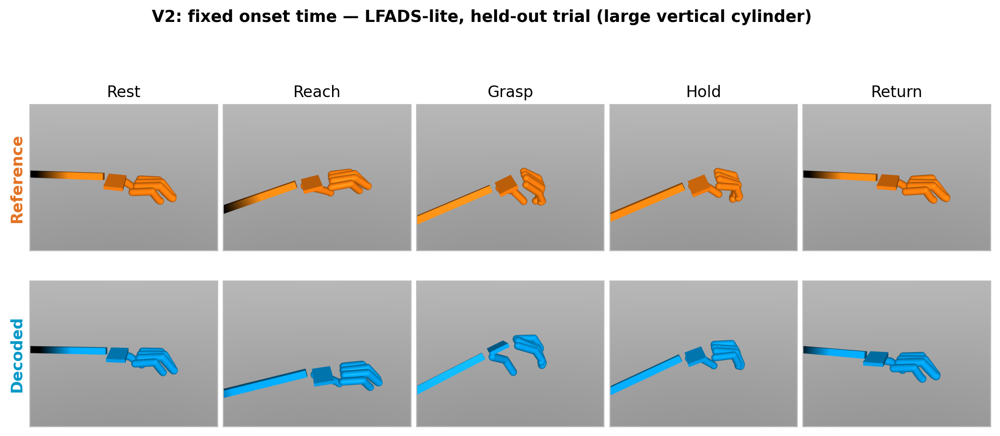

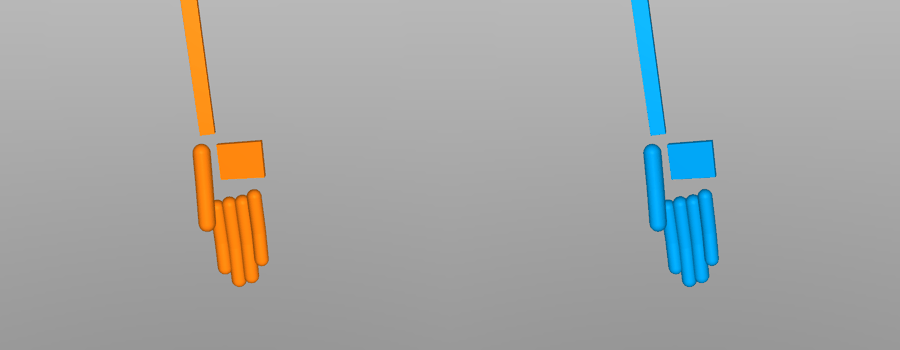

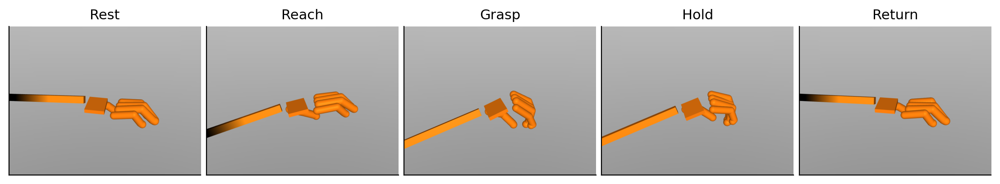

In [22]:
session = f'{SIM_DAY}-block{SIM_BLOCK}'
for name, r in runs.items():
    row, pairs, available = simulation.available_trials(ROOT, r)
    display(Markdown(f'**{RUN_TITLE[name]} — {describe(row)}**'))
    display(available.rename(columns={'session': 'day-block'}))
    chosen = available[available.session.eq(session) & available.trial.eq(SIM_TRIAL) & available.repetition.eq(SIM_REPETITION)]
    assert len(chosen), 'This trial is not in the test set with a saved replay; choose one from the table above.'
    print(f'Selected test trial: {session}, trial {SIM_TRIAL}, repetition {SIM_REPETITION + 1} of 10, object {chosen.object.iloc[0]}')
    simulation.replay_panel(ROOT, r, FIGURES, session=session, trial=SIM_TRIAL, repetition=SIM_REPETITION)
    plt.show()
    gif = simulation.replay_animation(ROOT, r, FIGURES, session=session, trial=SIM_TRIAL, repetition=SIM_REPETITION)
    display(Image(filename=str(gif), width=800))
simulation.reference_strip(ROOT, runs['v1'], FIGURES)

## 10. Causal 1Euro filtering (thesis Chapter 6)
**Method.** The 1Euro filter is applied to the decoded posture of every test trial; the jitter (computed within trials, see `jitter` in Section 4.1) and the pooled posture R² are compared before and after filtering.

In [23]:
# Figure of the filtering analysis
def filtering(r, out):
    """1Euro filter: within-trial jitter (top) and pooled accuracy (bottom), portrait layout."""
    b = r['board'][r['board'].split_mode.eq('repeat_holdout')]
    chosen = [candidate(r, True, family=f) for f in DIRECT] + [candidate(r, False)]
    rows = []
    for row in chosen:
        raw, euro = test_trials(r, row, 'raw'), test_trials(r, row, '1euro')
        rows.append(dict(experiment_id=row.experiment_id,
                         label=FAMILY_LABEL[row.model_family] + ('\nwith object ID' if row.condition_object else '\nwithout object ID'),
                         raw=raw.qpos_jitter.mean(), raw_sd=raw.qpos_jitter.std(),
                         filtered=euro.qpos_jitter.mean(), filtered_sd=euro.qpos_jitter.std(),
                         raw_R2=row.test_qpos_R2, filtered_R2=row.test_1euro_qpos_R2))
    data = pd.DataFrame(rows)
    x = np.arange(len(data))
    fig, axes = plt.subplots(2, 1, figsize=(8, 8.4), sharex=True)
    fig.subplots_adjust(left=.13, right=.98, top=.88, bottom=.12, hspace=.18)
    for off, key, label, color in [(-.19, 'raw', 'Decoder output', RAW_GREY), (.19, 'filtered', 'After 1Euro filter', FILTER_GREEN)]:
        axes[0].bar(x + off, data[key] * 1e4, yerr=data[key + '_sd'] * 1e4, width=.36, capsize=3, color=color,
                    edgecolor='#222', label=label)
        axes[1].bar(x + off, data[key + '_R2'], width=.36, color=color, edgecolor='#222')
        for i, v in enumerate(data[key + '_R2']):
            axes[1].text(i + off, v + .015, f'{v:.2f}', ha='center', va='bottom', fontsize=10)
    axes[0].set_ylabel('Jitter (10⁻⁴ rad per bin²)\nmean ± SD over test trials')
    axes[0].set_title('Jitter: how abruptly the decoded posture changes from bin to bin (lower = smoother)', fontsize=11)
    axes[1].set_ylabel('Test posture R²')
    axes[1].set_title('Accuracy of the decoded posture (higher = better)', fontsize=11)
    axes[1].set_ylim(0, 1)
    axes[1].set_xticks(x, data.label, fontsize=10)
    for ax in axes:
        ax.grid(axis='y', alpha=.22)
    fig.legend(*axes[0].get_legend_handles_labels(), loc='upper center', bbox_to_anchor=(.55, .955), ncol=2,
               frameon=False, fontsize=12)
    fig.suptitle(RUN_TITLE[r['run']] + ' — causal 1Euro filtering', y=.995, fontsize=15, fontweight='bold')
    return save(fig, out, f"{r['run']}_filtering", data)

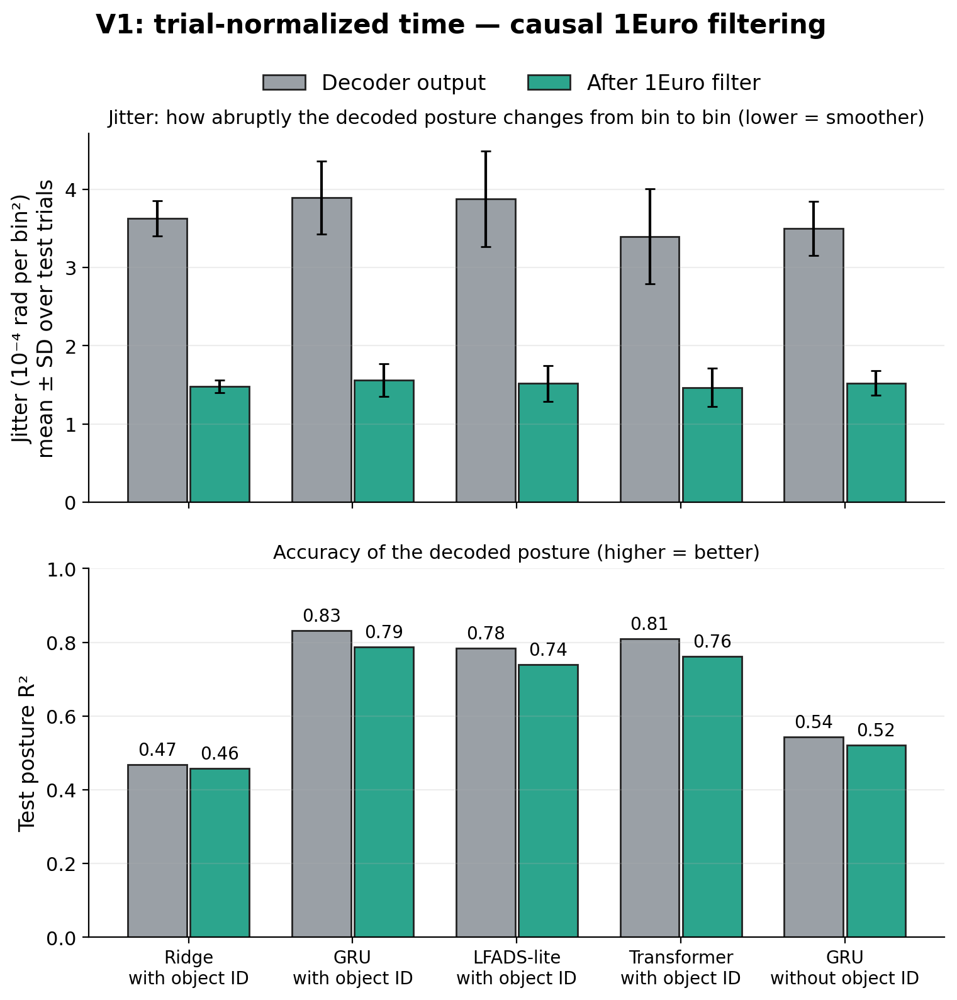

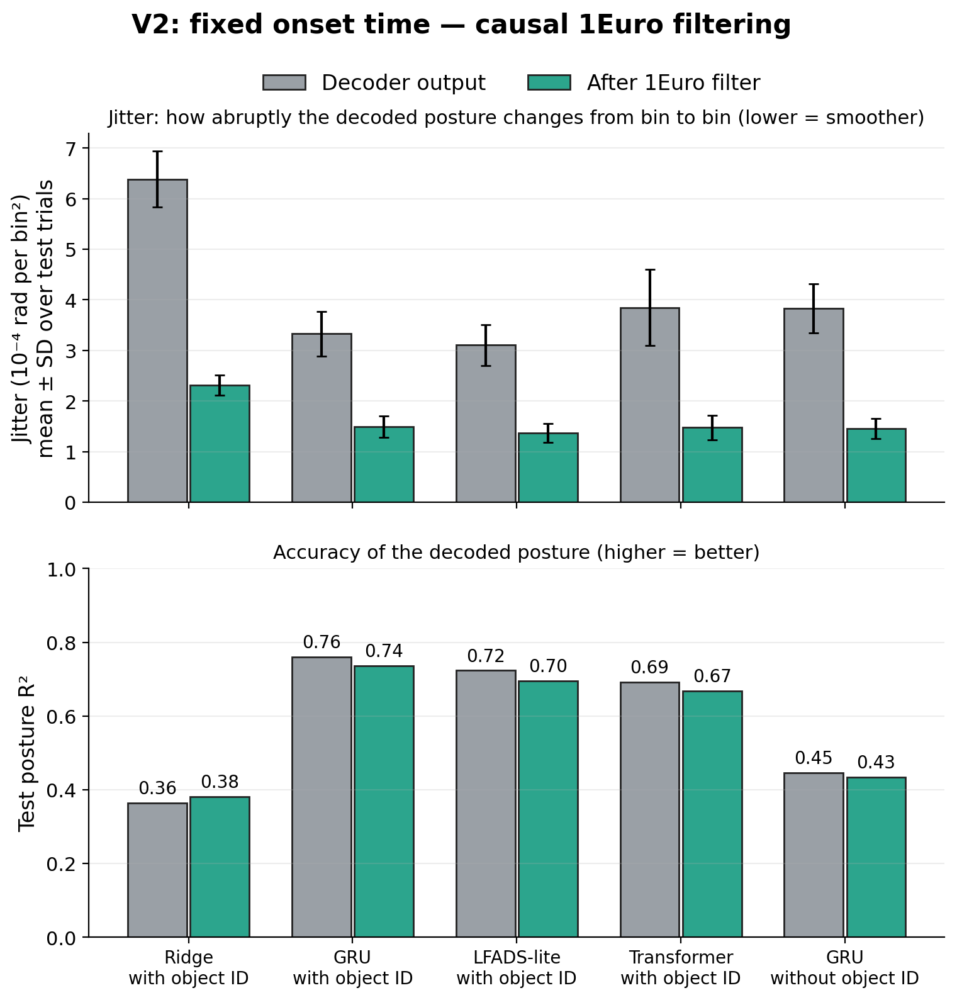

In [24]:
for name, r in runs.items():
    filtering(r, FIGURES)

**Answer.** The filter reduces the jitter by 60 % for the V1 GRU (R² 0.832 → 0.788) and by 56 % for the V2 LFADS-lite (R² 0.723 → 0.695); the other decoder families show reductions of 55–64 % with similarly small losses.

## 11. Summary of the results (thesis Chapter 7)
The object-conditioned GRU of V1 is the main decoder of the thesis (R² = 0.832 on new repetitions; about 0.01 ms of computation per bin offline). The LFADS-lite with the fixed onset clock of V2 (R² = 0.723) is a complementary candidate for movements whose duration is not known in advance. Unseen movement trajectories and a new recording day remain the main limitation. The table compares, for each holdout, the score of the configuration selected on validation with the highest test score observed in the grid, which shows how much optimism a test-based selection would introduce.

In [25]:
# Table comparing validation-based selection with the best test score
def selection(runs, out):
    """Validation-selected score next to the best score observed on the test set (descriptive)."""
    rows = []
    for split in SPLITS:
        entry = {'Holdout': SPLIT_SHORT[split]}
        for name, r in runs.items():
            b = r['board'][r['board'].split_mode.eq(split)]
            chosen = select(b, ['split_mode']).iloc[0]
            best = select(b, ['split_mode'], 'test_qpos_R2').iloc[0]
            entry[f'{name.upper()} selected on validation'] = f'{chosen.test_qpos_R2:.3f} ({FAMILY_LABEL[chosen.model_family]})'
            entry[f'{name.upper()} highest test value'] = f'{best.test_qpos_R2:.3f} ({FAMILY_LABEL[best.model_family]})'
        rows.append(entry)
    return _write(pd.DataFrame(rows), out, 'selection_comparison', 'lllll')

In [26]:
display(selection(runs, TABLES))

,Holdout,V1 selected on validation,V1 highest test value,V2 selected on validation,V2 highest test value
0,Repeat,0.832 (GRU),0.832 (GRU),0.723 (LFADS-lite),0.761 (GRU)
1,Gesture,0.432 (Transformer),0.483 (Transformer),0.309 (Transformer),0.416 (GRU)
2,Session,0.565 (Transformer),0.702 (Transformer),0.415 (GRU),0.503 (LFADS-lite)
3,Block,0.436 (GRU),0.487 (GRU),0.432 (GRU),0.433 (LFADS-lite)


## Appendix A. Artificial-stream tests of a decoder node (V1)
The V1 decoders were packaged as a streaming node and tested with artificial random spike counts and an external decode flag. These records concern the activation of the node and the computation time per update, not decoding accuracy; they include no signal acquisition, transport or actuator delays, so the latency of a complete online control loop cannot be measured from them.

In [27]:
# Figures of the artificial-stream tests
def artificial_input(n_bins=600):
    """Regenerate the artificial spike counts used in the recorded stream test."""
    rng = np.random.default_rng(STREAM_SEED)
    return np.stack([rng.poisson(lam=FAKE_RATE_HZ / RATE_HZ, size=256) for _ in range(n_bins)])


def gating_timeline(results, out):
    """Input stream, decode flag and published posture for the V1 GRU with object ID."""
    stream = pd.read_csv(Path(results) / 'brand_stream_tests/brand_node_artificial_gru_obj.csv')
    t = stream.timestamp_s.to_numpy()
    active = stream.decode_enabled.astype(bool).to_numpy()
    spikes = artificial_input(len(stream))
    fig, axes = plt.subplots(3, 1, figsize=(9.5, 6.6), sharex=True, gridspec_kw={'height_ratios': [1.6, .55, 2]})
    fig.subplots_adjust(left=.12, right=.8, top=.95, bottom=.08, hspace=.18)
    rows, cols = np.nonzero(spikes[:, :64].T)                    # first 64 channels for legibility
    axes[0].scatter(t[cols], rows, s=1.2, color='#333333', marker='|')
    axes[0].set_ylabel('Artificial input\n(channels 1-64)')
    axes[0].set_title('Artificial neural input (Poisson counts, 5 Hz per channel)', fontsize=12, loc='left')
    axes[1].fill_between(t, 0, active.astype(float), step='post', color='#2ca58d', alpha=.85)
    axes[1].set_yticks([0, 1], ['off', 'on'])
    axes[1].set_ylabel('Decode\nflag')
    for name, color in [('qpos_0', '#4e79a7'), ('qpos_3', '#76b7b2'), ('qpos_12', '#e15759'), ('qpos_22', '#c9a227')]:
        axes[2].plot(t, stream[name], color=color, lw=1.8, label=SHOWN[int(name.split('_')[1])])
    axes[2].set_ylabel('Published posture (rad)')
    axes[2].set_xlabel('Stream time (s)')
    axes[2].legend(loc='center left', bbox_to_anchor=(1.01, .5), frameon=False, fontsize=10.5)
    for ax in axes:
        ax.axvspan(t[active][0], t[active][-1], color='#2ca58d', alpha=.06)
        ax.grid(axis='x', alpha=.2)
    for x0 in (t[0] + .5, t[active][-1] + .5):
        axes[2].text(x0, axes[2].get_ylim()[0] + .1 * np.ptp(axes[2].get_ylim()), 'flag off:\nno output', ha='center', fontsize=9.5, color='#555555')
    source = stream[['timestamp_s', 'decode_enabled', 'phase', 'latency_ms', 'qpos_0', 'qpos_3', 'qpos_12', 'qpos_22']]
    return save(fig, out, 'brand_gating_timeline', source)


def latency(results, out):
    """Median and 95th-percentile per-bin decoding time of the tested V1 decoders."""
    folder = Path(results) / 'brand_stream_tests'
    rows = []
    for name, label, fam in [('brand_node_artificial_gru_obj', 'GRU\n(test 1)', 'gru'),
                             ('brand_node_artificial_repeat_holdout__none__gru__direct__obj__target_qpos_gru_direct_obj_qpos_pt', 'GRU\n(test 2)', 'gru'),
                             ('brand_node_artificial_lfads_obj', 'LFADS-lite', 'lfads_lite'),
                             ('brand_node_artificial_transformer_obj', 'Transformer', 'transformer')]:
        s = json.loads((folder / f'{name}.json').read_text())
        rows.append(dict(model=label, family=fam, median_ms=s['median_latency_ms'], p95_ms=s['p95_latency_ms'],
                         decoded_bins=s['n_decoded_bins']))
    data = pd.DataFrame(rows)
    x = np.arange(len(data))
    fig, ax = plt.subplots(figsize=(8, 4.3))
    fig.subplots_adjust(left=.11, right=.98, top=.86, bottom=.17)
    ax.bar(x - .18, data.median_ms, width=.34, color=[FAMILY_COLOR[f] for f in data.family], edgecolor='#222', label='Median')
    ax.bar(x + .18, data.p95_ms, width=.34, color=[FAMILY_COLOR[f] for f in data.family], edgecolor='#222', alpha=.45,
           hatch='//', label='95th percentile')
    for i, r in data.iterrows():
        ax.text(i - .18, r.median_ms * 1.12, f'{r.median_ms:.2f}', ha='center', fontsize=10)
        ax.text(i + .18, r.p95_ms * 1.12, f'{r.p95_ms:.2f}', ha='center', fontsize=10)
    ax.axhline(10, color='#c44e52', ls='--', lw=1.5)
    ax.text(len(data) - .55, 11.5, '10 ms budget (one bin at 100 Hz)', ha='right', color='#c44e52', fontsize=10.5)
    ax.set_yscale('log')
    ax.set_ylim(.03, 30)
    ax.set_xticks(x, data.model)
    ax.set_ylabel('Decoding time per bin (ms, log scale)')
    ax.grid(axis='y', alpha=.2, which='both')
    fig.legend(*ax.get_legend_handles_labels(), loc='upper center', ncol=2, frameon=False, fontsize=11)
    return save(fig, out, 'brand_latency', data)

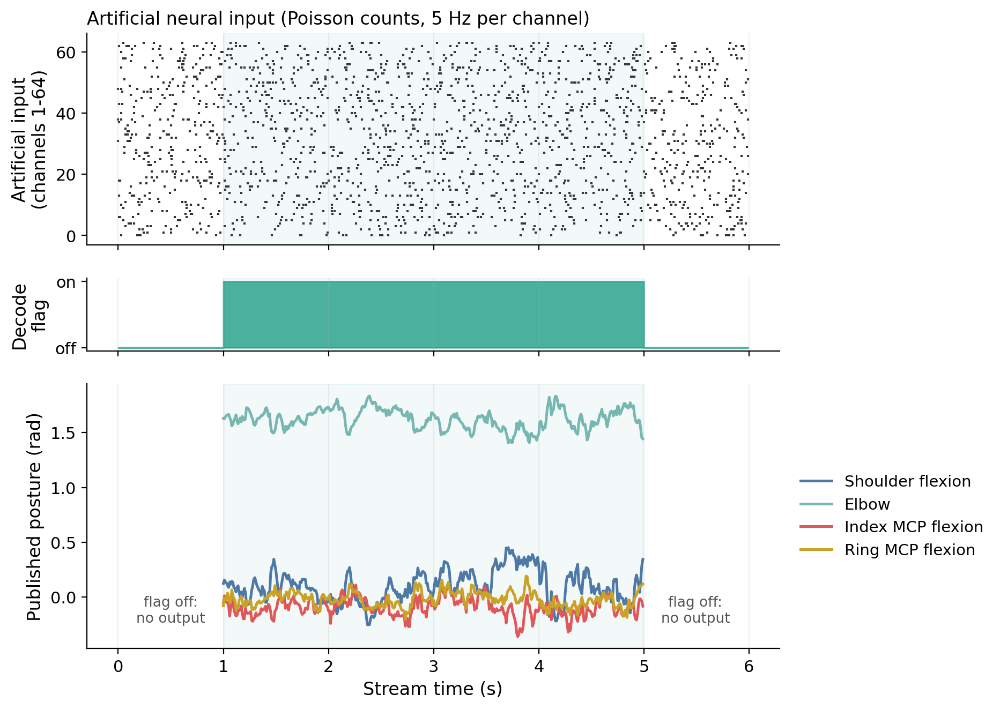

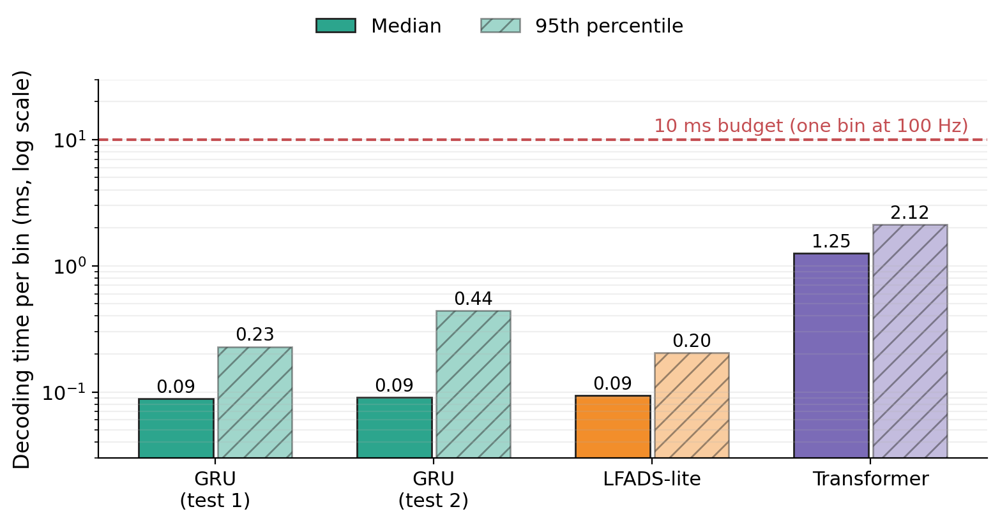

In [28]:
gating_timeline(ROOT / 'run_v1/results', FIGURES)
latency(ROOT / 'run_v1/results', FIGURES)

## Appendix B. Supporting figures: object-wise scores per recording day and replays of all objects

In [29]:
# Object-wise scores per recording day
def object_by_day(r, out):
    """Trial mean ± SD of posture R² per object, separately for each recording day (object-conditioned candidate)."""
    row = candidate(r, True)
    trials = test_trials(r, row)
    days = sorted(trials.session_date.unique())
    fig, axes = plt.subplots(1, len(days), figsize=(11, 4.4), sharey=True)
    fig.subplots_adjust(left=.07, right=.99, top=.8, bottom=.3, wspace=.06)
    frames = []
    for k, (ax, day) in enumerate(zip(axes, days)):
        g = trials[trials.session_date.eq(day)].groupby('object_name').qpos_R2.agg(['mean', 'std', 'size']).reindex(OBJECTS)
        frames.append(g.reset_index().assign(day=k + 1))
        ax.bar(range(6), g['mean'], yerr=g['std'], capsize=3, color=[OBJECT_COLOR[o] for o in OBJECTS], edgecolor='#222', lw=.6)
        ax.set_xticks(range(6), [OBJECT_LABEL[o] for o in OBJECTS], rotation=40, ha='right', fontsize=9)
        ax.axhline(0, color='#555', lw=.8)
        ax.grid(axis='y', alpha=.22)
        ax.set_title(f'Recording day {k + 1}', fontsize=12)
    axes[0].set_ylabel('Posture R² per test trial (mean ± SD)')
    fig.suptitle(f"{RUN_TITLE[r['run']]} — {FAMILY_LABEL[row.model_family]} with object ID", fontsize=13, fontweight='bold')
    return save(fig, out, f"{r['run']}_object_by_day", pd.concat(frames))

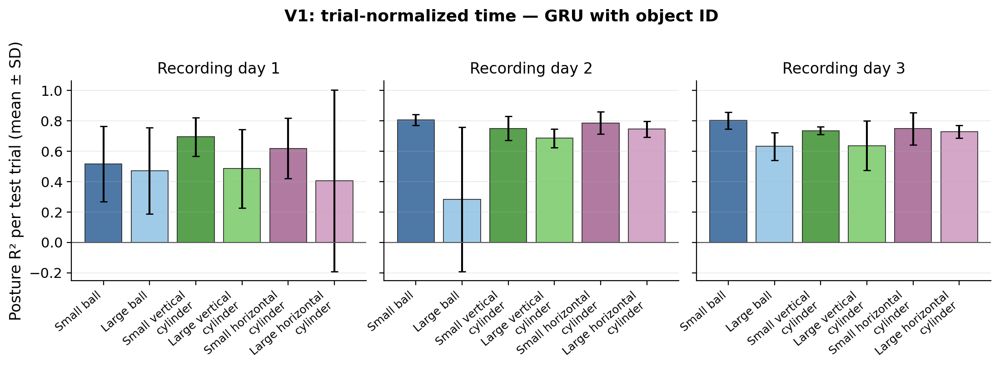

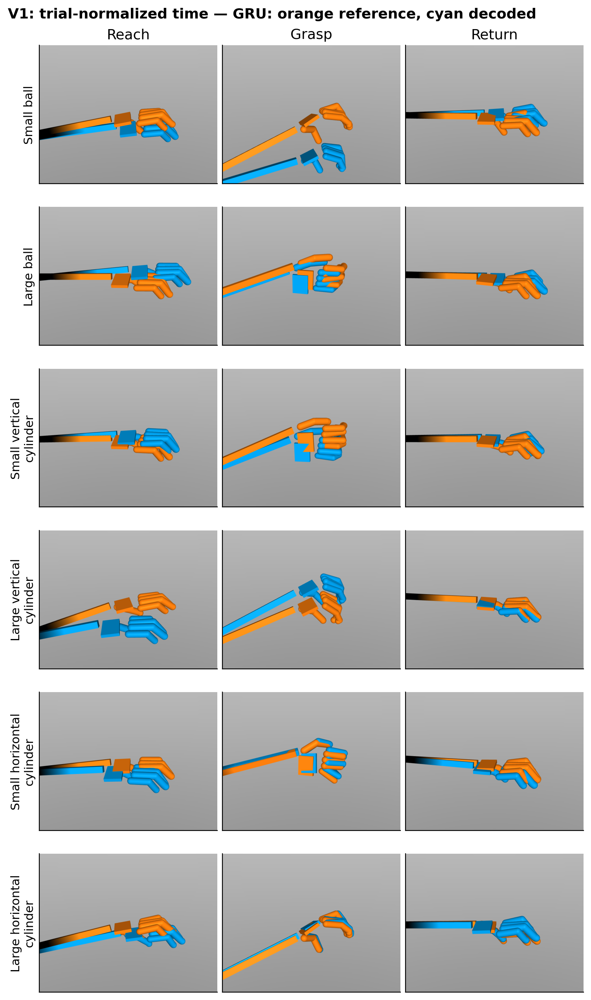

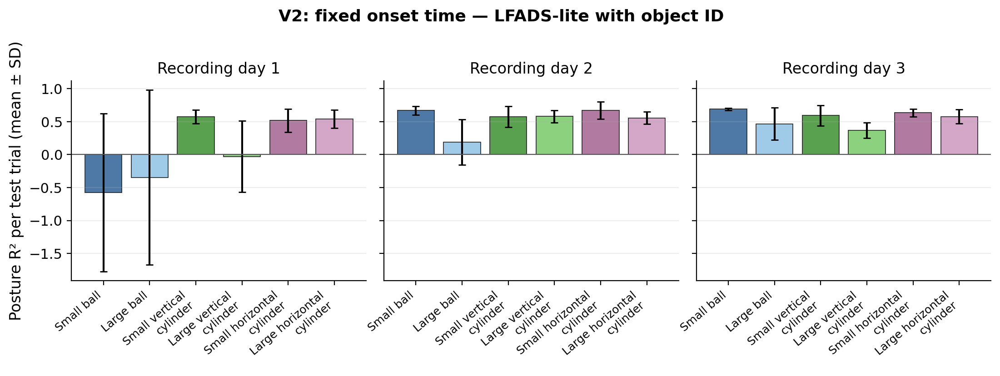

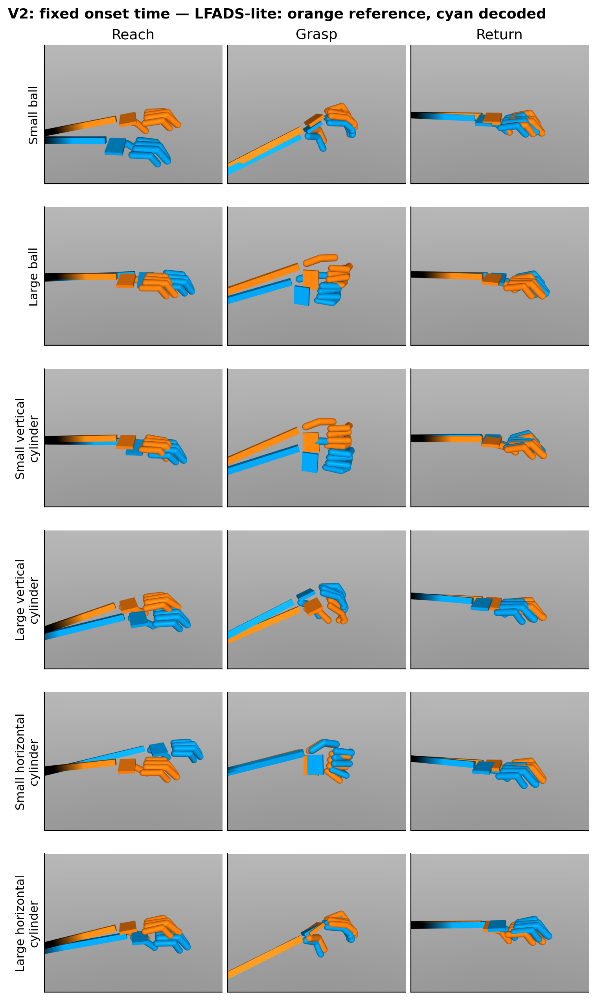

In [30]:
for name, r in runs.items():
    object_by_day(r, FIGURES)
    simulation.six_objects(ROOT, r, FIGURES)
    plt.show()

## Appendix C. Supporting tables
The selected configurations of all holdouts (Section 5), the raw-target scores (Sections 6 and 7) and the comparison of validation-selected and highest test scores (Section 11) are shown above; the trial-level scores per recording day and per block follow here.

In [31]:
# Trial-level variability per day and block
def variability(r, out):
    """Trial mean and SD of posture R2 per recording day and per block for the candidate."""
    row = candidate(r, True)
    trials = test_trials(r, row)
    tables = {}
    for key, label, name in [('session_date', 'Recording day', 'day'), ('block', 'Block', 'block')]:
        g = trials.groupby(key).agg(n=('qpos_R2', 'size'), mean=('qpos_R2', 'mean'), sd=('qpos_R2', 'std'),
                                    cc=('qpos_CC', 'mean'), rmse=('qpos_RMSE', 'mean')).reset_index()
        g[key] = g[key].map(DATE_LABEL) if key == 'session_date' else 'Block ' + g[key].astype(str)
        g.columns = [label, 'Test trials', 'Mean R2', 'SD R2', 'Mean CC', 'Mean RMSE (rad)']
        tables[name] = _write(g, out, f"{r['run']}_{name}_variability", 'lrrrrr')
    return tables

In [32]:
for name, r in runs.items():
    display(Markdown(f'**{RUN_TITLE[name]}**'))
    for table in variability(r, TABLES).values():
        display(table.round(3))

**V1: trial-normalized time**

,Recording day,Test trials,Mean R2,SD R2,Mean CC,Mean RMSE (rad)
0,Day 1,36,0.532,0.314,0.845,0.090
1,Day 2,36,0.677,0.262,0.880,0.074
2,Day 3,36,0.715,0.106,0.883,0.076


,Block,Test trials,Mean R2,SD R2,Mean CC,Mean RMSE (rad)
0,Block 1,36,0.606,0.286,0.867,0.084
1,Block 2,36,0.667,0.172,0.875,0.075
2,Block 3,36,0.651,0.289,0.866,0.080


**V2: fixed onset time**

,Recording day,Test trials,Mean R2,SD R2,Mean CC,Mean RMSE (rad)
0,Day 1,36,0.114,0.851,0.753,0.121
1,Day 2,36,0.540,0.231,0.805,0.098
2,Day 3,36,0.555,0.168,0.814,0.097


,Block,Test trials,Mean R2,SD R2,Mean CC,Mean RMSE (rad)
0,Block 1,36,0.312,0.669,0.778,0.111
1,Block 2,36,0.313,0.628,0.772,0.110
2,Block 3,36,0.584,0.205,0.822,0.094


## Appendix D. Posture trajectories of all joints (V1)
All 32 posture coordinates of one held-out trial per object: the reference, the GRU with object ID and the Transformer without object ID (the same test trial for both models). Portrait pages for the thesis and 16:9 versions for slides (`figures/presentation`); the trial selection and page layout are larger functions in `plotting_functions/presentation.py`.

,object,session,gesture,repeat,samples,gru_rmse_rad,transformer_rmse_rad,gru_experiment,transformer_experiment
0,small_ball,20260630-block1,7,8,543,0.107,0.103,repeat_holdout__pca64__gru__direct__obj__targe...,repeat_holdout__pca64__transformer__direct__no...
1,big_ball,20260630-block1,6,8,581,0.085,0.112,repeat_holdout__pca64__gru__direct__obj__targe...,repeat_holdout__pca64__transformer__direct__no...
2,small_v_cylinder,20260630-block1,13,8,616,0.048,0.094,repeat_holdout__pca64__gru__direct__obj__targe...,repeat_holdout__pca64__transformer__direct__no...
3,big_v_cylinder,20260630-block1,12,8,653,0.098,0.151,repeat_holdout__pca64__gru__direct__obj__targe...,repeat_holdout__pca64__transformer__direct__no...
4,small_h_cylinder,20260630-block1,0,8,563,0.083,0.234,repeat_holdout__pca64__gru__direct__obj__targe...,repeat_holdout__pca64__transformer__direct__no...
5,big_h_cylinder,20260630-block1,5,8,560,0.089,0.128,repeat_holdout__pca64__gru__direct__obj__targe...,repeat_holdout__pca64__transformer__direct__no...


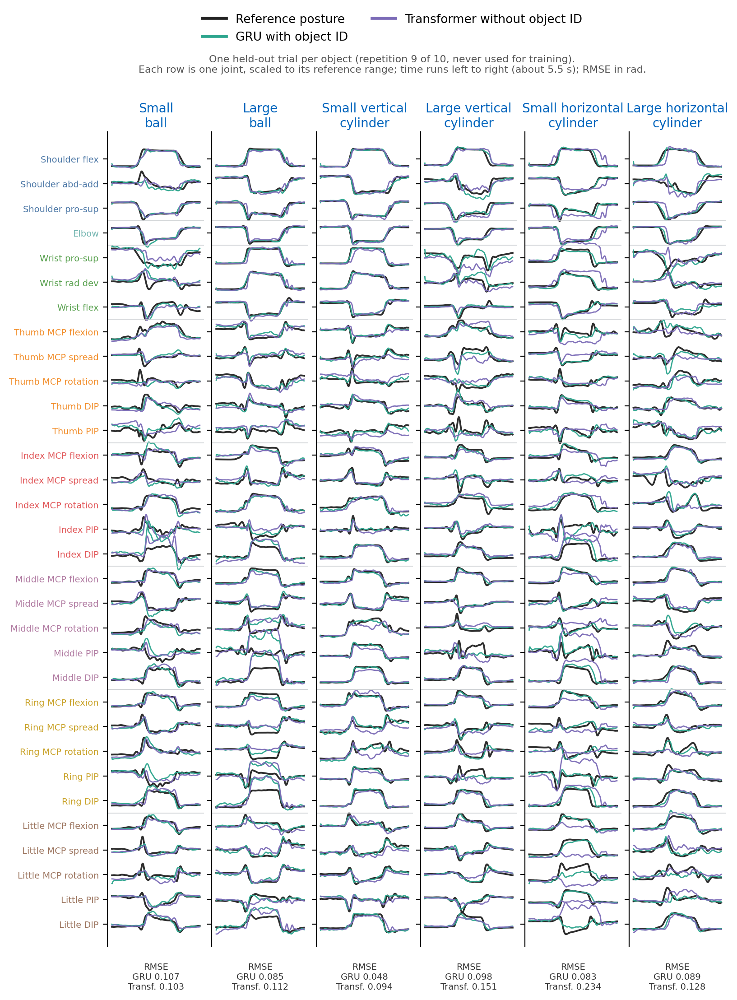

In [33]:
selected = presentation.appendix_pages(ROOT, runs['v1'], FIGURES)
presentation.generate(ROOT, runs['v1'], Path(FIGURES) / 'presentation')
display(selected.round(3))
names, chosen_trials, records = presentation.select_trials(ROOT, runs['v1'])
presentation.overview_figure(names, chosen_trials, records, portrait=True)
plt.show()

## Appendix E. Metric definitions
The metrics are defined in Appendix E of the thesis and implemented by the small functions of Section 4.1 (`r2`, `cc`, `rmse`, `shape_similarity`, `jitter`).

## One last figure

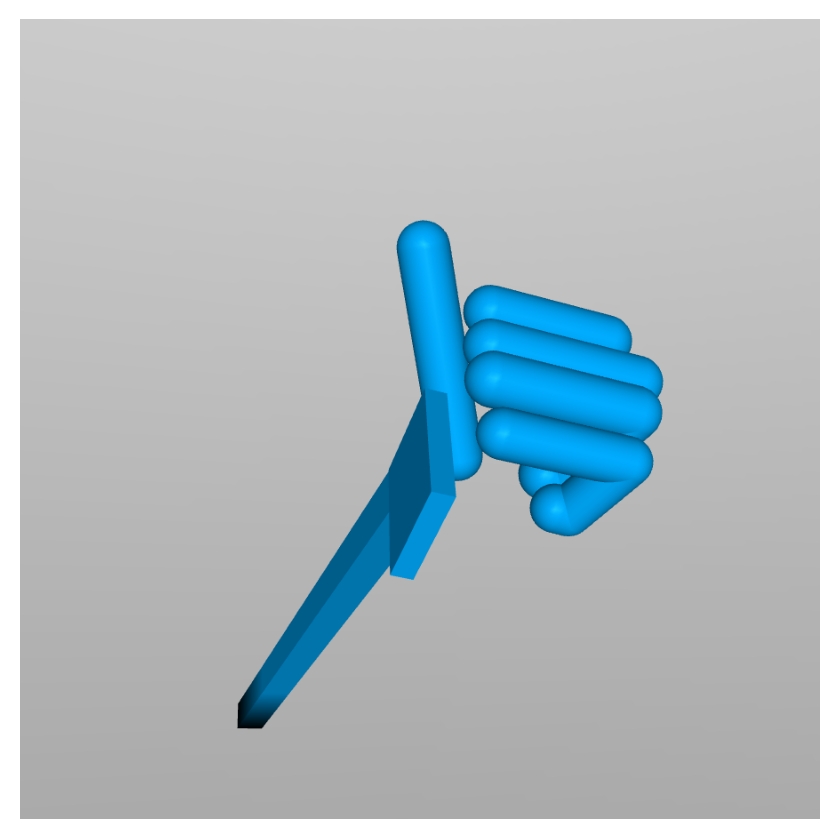

In [34]:
simulation.thanks(ROOT, FIGURES)